# Machine Learning for Sound and Music 2026
## Lab 1: Music Genre Classification part 2
##### Author: Lidia Wiśniewska
-----
### Background
Automatic genre classification using machine learning techniques is pivotal in managing
and enriching large-scale text and music collections. In textual data, assigning genre
labels—such as promotional or legal—enhances information retrieval by enabling users
to filter documents based on their specific needs, thereby improving search relevance and
efficiency. This automated labeling also aids in the curation of web corpora, ensuring a
diverse and representative dataset for training language models, which is essential for
advancing natural language processing applications. 

In the realm of music, genre classification facilitates the organization of extensive audio libraries, supporting
personalized recommendation systems and efficient content-based music retrieval. By
analyzing audio features, machine learning models can accurately categorize tracks into
genres like classical, jazz, or hip-hop, enhancing user experience in music streaming
services. Overall, the integration of automatic genre classification streamlines the
management of vast information repositories, making them more accessible and user-
centric

---
### Approach
This notebook implements genre classification using traditional ML techniques:
* Logistic Regression
* kNN
* Decision Trees
* Random Forest
* ANN (MLP)
* SVM (RBF kernel)
* Histogram Gradient Boosting

---
### Structure
The notebook structure looks as follows: <br>
    1. [Data loading](#1-data-loading-and-eda)<br>
    2. [Feature engineering](#2-feature-engineering)<br>
    3. [Classification](#3-classification)<br>
    4. [Evaluation](#4-evaluation)<br>
    5. [Research questions](#5-research-questions)<br>

    

## 1. Data loading and EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 250)


In [2]:
f30_df = pd.read_csv("./data/features_30_sec.csv", sep=",")
f30_df.columns = f30_df.columns.str.strip() #erase the whitespaces
feature_colnames_30 = f30_df.columns.drop('label').tolist()

print(f"Shape: {f30_df.shape[0]} rows, {f30_df.shape[1]} columns\n")
f30_df.head(10)

Shape: 1000 rows, 60 columns



,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,1.297741e+05,2002.449060,85882.761315,3805.839606,9.015054e+05,0.083045,0.000767,-4.529724e-05,0.008172,0.000008,0.005698,123.046875,-113.570648,2564.207520,121.571793,295.913818,-19.168142,235.574432,42.366421,151.106873,-6.364664,167.934799,18.623499,89.180840,-13.704891,67.660492,15.343150,68.932579,-12.274110,82.204201,10.976572,63.386311,-8.326573,61.773094,8.803792,51.244125,-3.672300,41.217415,5.747995,40.554478,-5.162882,49.775421,0.752740,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,3.758501e+05,2039.036516,213843.755497,3550.522098,2.977893e+06,0.056040,0.001448,1.395807e-04,0.005099,-0.000178,0.003063,67.999589,-207.501694,7764.555176,123.991264,560.259949,8.955127,572.810913,35.877647,264.506104,2.907320,279.932922,21.510466,156.477097,-8.560436,200.849182,23.370686,142.555954,-10.099661,166.108521,11.900497,104.358612,-5.555639,105.173630,5.376327,96.197212,-2.231760,64.914291,4.220140,73.152534,-6.012148,52.422142,0.927998,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,1.564676e+05,1747.702312,76254.192257,3042.260232,7.840345e+05,0.076291,0.001007,2.105576e-06,0.016342,-0.000019,0.007458,161.499023,-90.722595,3319.044922,140.446304,508.765045,-29.093889,411.781219,31.684334,144.090317,-13.984504,155.493759,25.764742,74.548401,-13.664875,106.981827,11.639934,106.574875,-11.783643,65.447945,9.718760,67.908859,-13.133803,57.781425,5.791199,64.480209,-8.907628,60.385151,-1.077000,57.711136,-9.229274,36.580986,2.451690,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,1.843559e+05,1596.412872,166441.494769,2184.745799,1.493194e+06,0.033309,0.000423,4.583644e-07,0.019054,-0.000014,0.002712,63.024009,-199.544205,5507.517090,150.090897,456.505402,5.662678,257.161163,26.859079,158.267303,1.771399,268.034393,14.234031,126.794128,-4.832006,155.912079,9.286494,81.273743,-0.759186,92.114090,8.137607,71.314079,-3.200653,110.236687,6.079319,48.251999,-2.480174,56.799400,-1.079305,62.289902,-2.870789,51.651592,0.780874,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,3.433999e+05,1748.172116,88445.209036,3579.757627,1.572978e+06,0.101461,0.001954,-1.756129e-05,0.004814,-0.000010,0.003094,135.999178,-160.337708,5195.291992,126.219635,853.784729,-35.587811,333.792938,22.148071,193.456100,-32.478600,336.276825,10.852294,134.831573,-23.352329,93.257095,0.498434,124.672127,-11.793437,130.073349,1.207256,99.675575,-13.088418,80.254066,-2.813867,86.430626,-6.933385,89.555443,-7.552725,70.943336,-9.164666,75.793404,-4.520576,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
5,blues.00005.wav,661794,0.302456,0.087532,0.103494,0.003981,1831.993940,1.030482e+06,1729.653287,201910.508633,3481.517592,3.274440e+06,0.094042,0.0062

In [3]:
f3_df = pd.read_csv("./data/features_3_sec.csv", sep=",")
f3_df.columns = f3_df.columns.str.strip() #erase the whitespaces
feature_colnames_3 = f3_df.columns.drop('label').tolist()

print(f"Shape: {f3_df.shape[0]} rows, {f3_df.shape[1]} columns\n")
f3_df.head(10)

Shape: 9990 rows, 60 columns



,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,1.080790e+06,0.081851,0.000558,-0.000078,0.008354,-0.000068,0.005535,129.199219,-118.627914,2440.286621,125.083626,260.956909,-23.443724,364.081726,41.321484,181.694855,-5.976108,152.963135,20.115141,75.652298,-16.045410,40.227104,17.855198,84.320282,-14.633434,83.437233,10.270527,97.001335,-9.708279,66.669891,10.183875,45.103611,-4.681614,34.169498,8.417439,48.269444,-7.233477,42.770947,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,6.722448e+05,0.087173,0.001030,-0.000099,0.004950,-0.000103,0.004854,123.046875,-125.590706,2038.344238,122.421227,216.774185,-20.718019,231.979767,50.128387,142.700409,-11.333302,139.243118,21.385401,77.817947,-15.960796,97.364029,19.454103,57.948093,-12.465918,68.271523,17.898169,56.222176,-11.732554,54.373909,8.145000,40.662876,-7.717751,30.808521,8.397150,48.784225,-8.300493,68.584824,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,7.907127e+05,0.071383,0.000425,-0.000066,0.012476,0.000065,0.004357,123.046875,-132.441940,3798.532227,115.085175,257.321289,-14.811666,192.448074,50.189293,144.166031,-0.680819,128.376892,24.650375,66.371170,-13.506104,89.319336,15.643386,55.253967,-13.216637,120.308784,10.406025,35.757862,-7.991465,47.911613,11.853963,36.569931,-4.677677,40.725075,6.571110,30.686846,-2.424750,50.313499,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,9.216524e+05,0.069426,0.000304,-0.000014,0.008318,0.000018,0.005927,123.046875,-118.231087,2508.781006,132.116501,332.650574,-18.758335,109.357529,39.769306,184.693344,-13.260426,144.398224,20.468134,122.516464,-14.563448,68.937332,18.745104,74.748886,-13.755463,73.868576,12.993759,41.549564,-12.648887,58.540478,10.389314,39.102024,-4.362739,60.714748,9.156193,40.411537,-9.889441,44.666325,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,6.102111e+05,0.070095,0.000289,0.000041,0.009634,-0.000106,0.005833,123.046875,-105.968376,2118.919922,134.643646,219.562622,-19.961748,171.878754,40.171753,103.120712,-14.271939,102.651230,18.734617,79.070000,-15.619381,48.510284,19.207966,53.642956,-18.274683,95.300995,14.316693,58.821163,-5.792194,55.030254,17.045437,43.229939,-5.681399,46.515259,5.705521,24.956211,-7.986080,39.816933,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues
5,blues.00000.5.wav,66149,0.376670,0.089702,0.132618,0.003583,1994.915219,211700.619569,2152.767854,74263.873102,4371.985614,1.067105e+06,0.092420,0.001174,-0.00003

We observe that the columns are the same for both datasets; `f3_df` has (about) 10 times more rows because every 30 s track is cut into ten 3 s clips (`blues.00000.wav` → `blues.00000.0.wav` … `blues.00000.9.wav`).

Every row of `f3_df` therefore belongs to a **song**, and clips of the same song are highly similar. All splits for F3 must be done by song, otherwise the model is tested on songs it has already seen.

In [4]:
#f30_df
missing_counts = f30_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
if missing_counts.empty:
    print("No missing values found.")
else:
    print(missing_counts.to_string())

Missing values by column:
No missing values found.


In [5]:
#f3_df
missing_counts = f3_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

print("Missing values by column:")
if missing_counts.empty:
    print("No missing values found.")
else:
    print(missing_counts.to_string())

Missing values by column:
No missing values found.


In [ ]:
# Audio descriptors only
FEATURE_COLS = [c for c in f30_df.columns if c not in ("filename", "length", "label")]

# Song identifiers: "blues.00000.wav" -> "blues.00000", "blues.00000.3.wav" -> "blues.00000"
f30_df["song_id"] = f30_df["filename"].str.replace(r"\.wav$", "", regex=True)
f3_df["song_id"] = f3_df["filename"].astype(str).str.extract(r"^(.*?\.\d+)(?:\.\d+)?\.wav$", expand=False)
assert f3_df["song_id"].notna().all(), "Could not derive song IDs from every F3 filename."
assert set(f3_df["song_id"]) == set(f30_df["song_id"]), "F3 and F30 do not describe the same songs."
assert f3_df.groupby("song_id")["label"].nunique().max() == 1, "A song has clips with different genres."

dup_30 = f30_df[f30_df.duplicated(subset=FEATURE_COLS, keep=False)]
print(f"F30 duplicate rows (features only): {len(dup_30)}")
dup_30.sort_values(by=FEATURE_COLS[:3])[["filename", "label"] + FEATURE_COLS[:3]]

F30 duplicate rows (features only): 28


,filename,label,chroma_stft_mean,chroma_stft_var,rms_mean
754,pop.00054.wav,pop,0.390280,0.099812,0.273480
760,pop.00060.wav,pop,0.390280,0.099812,0.273480
439,hiphop.00039.wav,hiphop,0.392812,0.101583,0.184535
445,hiphop.00045.wav,hiphop,0.392812,0.101583,0.184535
634,metal.00034.wav,metal,0.406933,0.083121,0.090511
694,metal.00094.wav,metal,0.406933,0.083121,0.090511
476,hiphop.00076.wav,hiphop,0.424605,0.097809,0.237200
478,hiphop.00078.wav,hiphop,0.424605,0.097809,0.237200
645,metal.00045.wav,metal,0.430214,0.081088,0.088064
666,metal.00066.wav,metal,0.430214,0.081088,0.088064


In [7]:
dup_3 = f3_df[f3_df.duplicated(subset=FEATURE_COLS, keep=False)]
print(f"F3 duplicate rows (features only): {len(dup_3)}")

def duplicate_song_sets(df):
    key = pd.util.hash_pandas_object(df[FEATURE_COLS], index=False)
    dup = df.assign(_key=key)[key.duplicated(keep=False)]
    return dup.groupby("_key")["song_id"].apply(lambda s: tuple(sorted(set(s)))).value_counts()

print("\nSongs sharing identical F3 clips (number of identical clips):")
print(duplicate_song_sets(f3_df).to_string())

F3 duplicate rows (features only): 286

Songs sharing identical F3 clips (number of identical clips):
song_id
(metal.00045, metal.00066)      10
(metal.00040, metal.00061)      10
(metal.00043, metal.00064)      10
(metal.00034, metal.00094)      10
(disco.00098, disco.00099)      10
(pop.00067, pop.00071)          10
(metal.00044, metal.00065)      10
(metal.00041, metal.00062)      10
(reggae.00081, reggae.00082)    10
(hiphop.00039, hiphop.00045)    10
(metal.00042, metal.00063)      10
(hiphop.00076, hiphop.00078)    10
(pop.00054, pop.00060)          10
(metal.00058, rock.00016)       10
(reggae.00073, reggae.00074)     3


Checking duplicates on the audio features only (the original check included `filename`, which is unique, so it could never find anything) reveals following repetitions:

* **14 pairs of identical tracks** in F30 (mostly metal, plus disco, hip-hop, pop and reggae). One pair is **mislabeled**: `metal.00058` and `rock.00016` are the same audio with two different genres. These are the same 14 pairs we found in Task 1.
* In F3 the same 14 pairs appear as 10 identical clips each, plus `reggae.00073` / `reggae.00074`, which share 3 identical clips (overlapping excerpts of the same recording).

If one copy lands in train and the other in test, the model is tested on a song it has memorised. We handle this exactly as in Task 1, and identically for both datasets:

1. the mislabeled pair is dropped completely;
2. for the other exact pairs the first copy is kept;
3. partially overlapping songs (`reggae.00073/74`) are kept but put into the same **group**, so they always end up on the same side of a split.

In [8]:
# Union-find over songs that share identical feature rows (in F30 or F3)
pairs_30 = list(duplicate_song_sets(f30_df).index)
pairs_all = pairs_30 + list(duplicate_song_sets(f3_df).index)

parent = {s: s for s in f30_df["song_id"]}
def find(s):
    while parent[s] != s:
        s = parent[s]
    return s
for songs in pairs_all:
    root = find(songs[0])
    for s in songs[1:]:
        parent[find(s)] = root

song_label = f30_df.set_index("song_id")["label"]
songs_to_drop = set()
for songs in pairs_30:                       # exact duplicate tracks
    if song_label[list(songs)].nunique() > 1:
        songs_to_drop |= set(songs)          # conflicting genres -> drop both
    else:
        songs_to_drop |= set(songs[1:])      # same genre -> keep the first copy

f30_df = f30_df[~f30_df["song_id"].isin(songs_to_drop)].reset_index(drop=True)
f3_df = f3_df[~f3_df["song_id"].isin(songs_to_drop)].reset_index(drop=True)
f30_df["group"] = f30_df["song_id"].map(find)
f3_df["group"] = f3_df["song_id"].map(find)

print(f"Dropped songs ({len(songs_to_drop)}): {sorted(songs_to_drop)}")
print(f"F30: {f30_df.shape[0]} songs | F3: {f3_df.shape[0]} clips | groups: {f30_df['group'].nunique()}")
assert not f30_df.duplicated(subset=FEATURE_COLS).any()

Dropped songs (15): ['disco.00099', 'hiphop.00045', 'hiphop.00078', 'metal.00058', 'metal.00061', 'metal.00062', 'metal.00063', 'metal.00064', 'metal.00065', 'metal.00066', 'metal.00094', 'pop.00060', 'pop.00071', 'reggae.00082', 'rock.00016']
F30: 985 songs | F3: 9840 clips | groups: 984


#### Datatypes

In [9]:
print(f"Unique data types: {f30_df.dtypes.unique().tolist()}")
print("\nAll column data types:\n")
f30_df.dtypes

Unique data types: [<StringDtype(storage='python', na_value=nan)>, dtype('int64'), dtype('float64')]

All column data types:



filename                str
length                int64
chroma_stft_mean    float64
chroma_stft_var     float64
rms_mean            float64
                     ...   
mfcc20_mean         float64
mfcc20_var          float64
label                   str
song_id                 str
group                   str
Length: 62, dtype: object

The dataset contains only numeric (float) audio descriptors, plus `filename` (string), which is not a predictor but defines the song groups used for splitting. `length` (integer) is recording metadata: it is constant in F3 and only reflects the file length in F30, so it is excluded from the predictors.

In [10]:
cat_columns = pd.Index(["filename", "label"])
num_columns = pd.Index(FEATURE_COLS)          # predictors only (no length, no ids)
print(f"Predictors: {len(num_columns)}")

Predictors: 57


#### F30_df columns

In [11]:
feature_df_descr_30 = f30_df[num_columns].describe()
feature_df_descr_30

,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,985.000000,985.000000,985.000000,985.000000,985.000000,9.850000e+02,985.000000,985.000000,985.000000,9.850000e+02,985.000000,985.000000,9.850000e+02,985.000000,985.000000,9.850000e+02,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000,985.000000
mean,0.377708,0.086357,0.130671,0.003019,2194.401419,4.679959e+05,2239.708783,137214.553882,4558.766613,1.843055e+06,0.103015,0.002962,-3.633935e-04,0.012513,-0.000387,5.633801e-03,119.475639,-145.378464,3755.779345,99.808780,707.670470,-8.718530,467.553298,36.237968,220.441827,-1.069504,174.666965,14.592108,126.708969,-5.105249,116.064337,10.019552,88.093280,-6.926235,88.527567,7.618218,81.716576,-5.969660,75.626440,4.411762,68.807421,-4.709354,67.974662,1.762939,64.811760,-3.853678,62.793961,1.104780,60.755815,-3.930262,62.562902,0.472011,63.764666,-2.287044,66.345604,-1.111018,70.347500
std,0.081853,0.007713,0.065751,0.003533,716.934563,3.989656e+05,527.245199,96524.414753,1578.032119,1.421321e+06,0.041718,0.003004,1.693248e-03,0.011587,0.001079,6.489042e-03,28.255694,100.622470,2771.874584,31.424699,439.539847,21.495328,286.330395,16.658343,116.012901,12.205204,101.007111,11.831828,67.753820,9.910421,58.229774,10.430359,40.876103,8.236488,39.479461,7.899217,36.637876,6.787031,38.194461,6.724065,32.710571,6.075290,33.265616,5.018819,34.618921,4.871486,33.890061,4.568452,33.895514,4.541486,33.571180,3.870506,34.543328,3.716703,37.338683,3.846866,45.443246
min,0.171939,0.044555,0.005276,0.000004,570.040355,7.911251e+03,898.066208,10787.185064,749.140636,1.468612e+04,0.021697,0.000044,-2.606458e-02,0.000049,-0.007150,8.299008e-07,54.978391,-552.120056,174.571365,-1.461542,93.104752,-89.870193,35.467754,-18.727547,34.263149,-38.890347,29.912008,-28.415911,20.847921,-32.930431,29.027332,-24.915823,22.464230,-31.640574,25.825863,-12.050177,19.273201,-28.057501,21.402756,-15.796446,18.642517,-27.523129,17.293922,-12.594489,14.250607,-17.539125,9.769691,-15.693844,9.169314,-17.234728,13.931521,-11.963694,15.420555,-18.501955,13.487622,-19.929634,7.956583
25%,0.319164,0.082461,0.086464,0.000943,1615.937513,1.843559e+05,1899.187435,67419.904728,3362.185676,7.728893e+05,0.069800,0.001059,-9.884714e-05,0.004430,-0.000498,1.243237e-03,99.384014,-202.057281,1853.268799,76.779915,399.071350,-23.832516,271.114410,24.121641,129.904068,-9.967194,101.798981,5.055660,76.445427,-12.846461,73.496849,1.604251,57.361359,-13.127577,59.869633,1.589508,55.853935,-10.809751,51.566658,-0.580041,47.022369,-9.255790,46.337204,-1.664248,43.419197,-7.108643,42.229267,-1.875381,40.402470,-7.139071,40.753147,-2.041274,41.883041,-4.604125,42.086014,-3.385912,42.573532
50%,0.380838,0.086656,0.122255,0.001822,2192.650290,3.381178e+05,2218.677679,112732.414725,4615.982658,1.489323e+06,0.098955,0.002017,-3.020536e-06,0.008768,-0.000034,3.405904e-03,117.453835,-121.142204,3144.944824,98.660759,607.724548,-10.658144,405.195770,36.82771

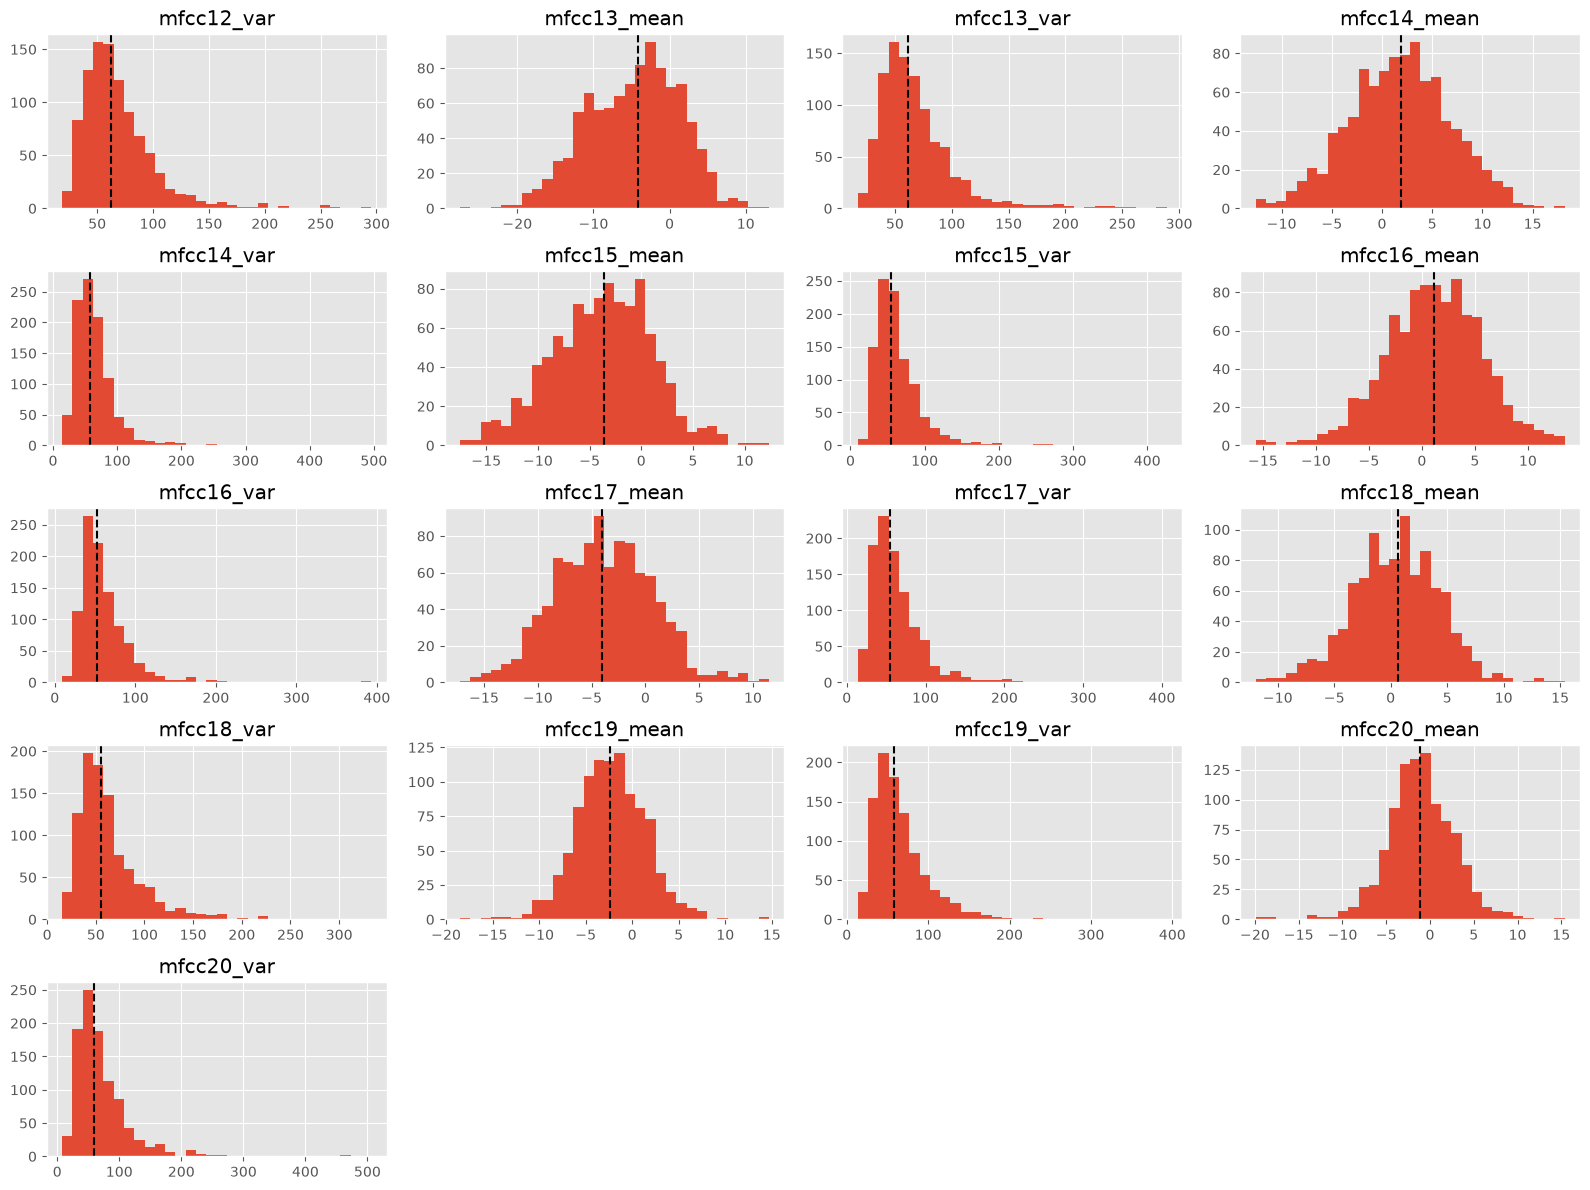

In [12]:
#distributions
with PdfPages("./data/task2_distributions_30.pdf") as pdf:
    for start in range(0, len(num_columns), 20):
        cols=num_columns[start:start+20]
        axes = f30_df[num_columns][cols].hist(bins=30, figsize=(16, 12))

        for ax, col in zip(axes.ravel(), cols):
            median = feature_df_descr_30.loc["50%", col]
            ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
        fig = axes.ravel()[0].figure
        fig.tight_layout()
        pdf.savefig(fig)

        if start + 20 < len(num_columns):
            plt.close(fig)
        last_fig = fig

if last_fig is not None:
    plt.show()

We observe highly unscaled data, some values are centered around 0, while other go up to value of 500. Additionally, we observe again various distributions across the columns.

In [13]:
#variance check
feature_df_descr_30.iloc[2, :].sort_values(ascending=True).head(10)


perceptr_mean              0.001079
harmony_mean               0.001693
zero_crossing_rate_var     0.003004
rms_var                    0.003533
perceptr_var               0.006489
chroma_stft_var            0.007713
harmony_var                0.011587
zero_crossing_rate_mean    0.041718
rms_mean                   0.065751
chroma_stft_mean           0.081853
Name: std, dtype: float64

Several features have low but non-zero standard deviation. Low variance alone is not a reason to drop an acoustic feature (its scale is arbitrary), so they are retained. None of the predictors is constant.

In [14]:
#mean check
feature_df_descr_30.iloc[1, :].sort_values(ascending=False).head(5)
mean_max = feature_df_descr_30.iloc[1, :].max()
mean_min = feature_df_descr_30.iloc[1, :].min()
print(f"The highest mean value: {mean_max}, the lowest mean value: {mean_min}")


The highest mean value: 1843055.0962629823, the lowest mean value: -145.37846374974637


The means range from about −145 (`mfcc1_mean`) to about 1.8·10⁶ (`rolloff_var`), i.e. the features differ by up to 9 orders of magnitude. Scaling is therefore mandatory for distance-based and gradient-based models (kNN, logistic regression, SVM, MLP).

In [15]:
#min check
feature_df_descr_30.iloc[3, :].sort_values(ascending=True).head(5)

mfcc1_mean   -552.120056
mfcc3_mean    -89.870193
mfcc5_mean    -38.890347
mfcc7_mean    -32.930431
mfcc9_mean    -31.640574
Name: min, dtype: float64

In [16]:
#max check
feature_df_descr_30.iloc[7, :].sort_values(ascending=False).head(10)

rolloff_var                8.660900e+06
spectral_centroid_var      3.036843e+06
spectral_bandwidth_var     6.947848e+05
mfcc1_var                  2.824344e+04
rolloff_mean               8.677673e+03
spectral_centroid_mean     4.435244e+03
mfcc2_var                  4.025973e+03
spectral_bandwidth_mean    3.509646e+03
mfcc3_var                  2.924435e+03
mfcc5_var                  1.083649e+03
Name: max, dtype: float64

In [17]:
# Skewness: the *_var features are strongly right-skewed (long tail of very large values)
skew_30 = f30_df[num_columns].skew().sort_values(ascending=False)
display(skew_30.head(10).round(2).to_frame("skew"))
var_columns = [c for c in num_columns if c.endswith("_var")]
print(f"Mean skew of the {len(var_columns)} *_var columns: {f30_df[var_columns].skew().mean():.2f} "
      f"-> after log1p: {np.log1p(f30_df[var_columns]).skew().mean():.2f}")

,skew
mfcc11_var,4.04
mfcc14_var,3.97
mfcc16_var,3.87
mfcc15_var,3.56
mfcc20_var,3.35
mfcc17_var,2.77
rms_var,2.67
zero_crossing_rate_var,2.58
mfcc19_var,2.53
mfcc1_var,2.52


Mean skew of the 28 *_var columns: 2.15 -> after log1p: 0.36


The variance features (`*_var`) are strongly right-skewed. A `RobustScaler` does not change the shape of a distribution, so after scaling those columns still have extreme values that dominate distances (kNN, SVM) and slow down or break the convergence of logistic regression (the `ConvergenceWarning`s in the previous version). Applying `log1p` to the `*_var` columns (they are all ≥ 0) makes them roughly symmetric; then a `StandardScaler` puts every feature on the same scale. This transformation is done **inside** the model pipelines.

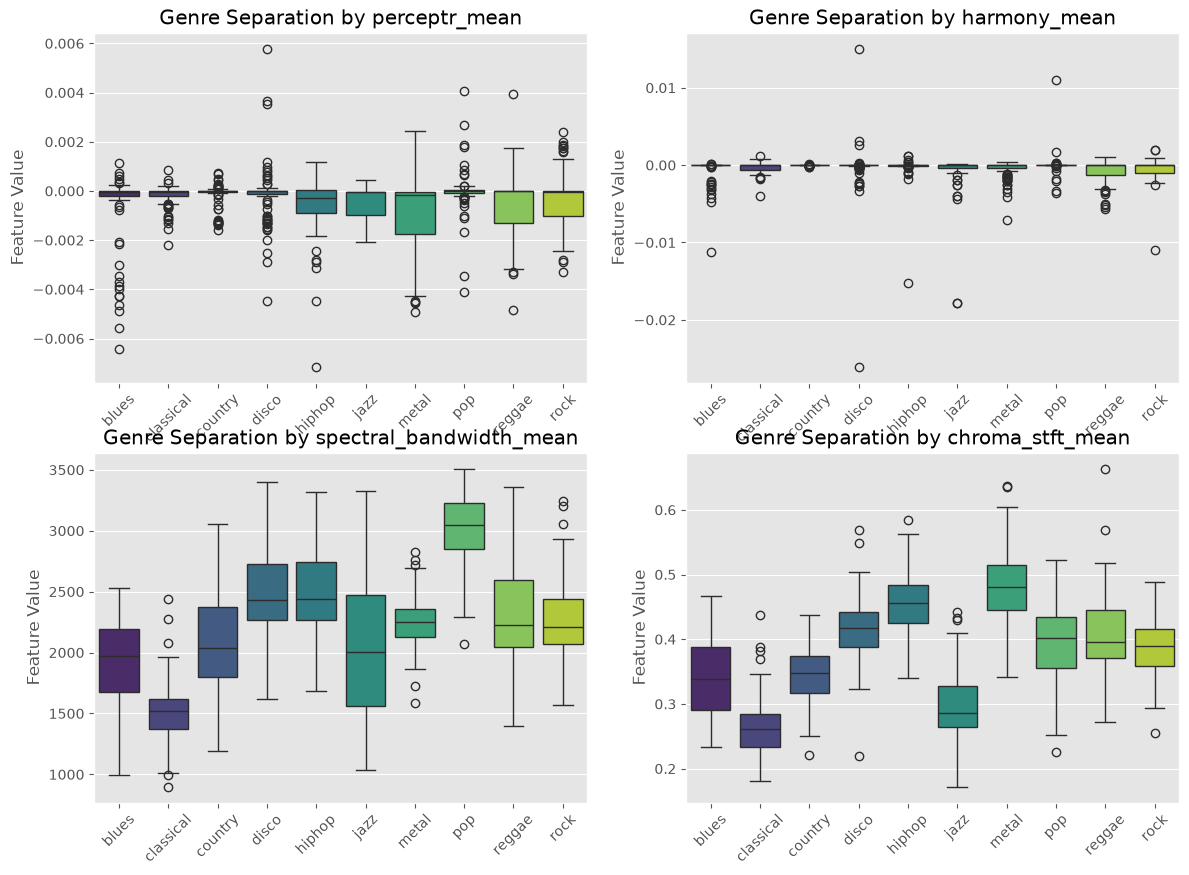

In [18]:
#primary target separation inspection
to_inspect = ["perceptr_mean",
              "harmony_mean",
              "spectral_bandwidth_mean",
              "chroma_stft_mean"
              ]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(to_inspect):
    sns.boxplot(data=f30_df, x='label', y=feature, ax=axes[i], hue="label",legend=False, palette='viridis')
    axes[i].set_title(f'Genre Separation by {feature}')
    axes[i].set_ylabel('Feature Value')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.show()

#### F3_df columns

In [19]:
feature_df_descr_3 = f3_df[num_columns].describe()
feature_df_descr_3

,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,rolloff_var,zero_crossing_rate_mean,zero_crossing_rate_var,harmony_mean,harmony_var,perceptr_mean,perceptr_var,tempo,mfcc1_mean,mfcc1_var,mfcc2_mean,mfcc2_var,mfcc3_mean,mfcc3_var,mfcc4_mean,mfcc4_var,mfcc5_mean,mfcc5_var,mfcc6_mean,mfcc6_var,mfcc7_mean,mfcc7_var,mfcc8_mean,mfcc8_var,mfcc9_mean,mfcc9_var,mfcc10_mean,mfcc10_var,mfcc11_mean,mfcc11_var,mfcc12_mean,mfcc12_var,mfcc13_mean,mfcc13_var,mfcc14_mean,mfcc14_var,mfcc15_mean,mfcc15_var,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,9840.000000,9840.000000,9840.000000,9.840000e+03,9840.000000,9.840000e+03,9840.000000,9.840000e+03,9840.000000,9.840000e+03,9840.000000,9840.000000,9840.000000,9.840000e+03,9840.000000,9.840000e+03,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000,9840.000000
mean,0.378586,0.084909,0.130602,2.643710e-03,2191.805931,4.146463e+05,2238.533826,1.182662e+05,4553.224880,1.626083e+06,0.101986,0.002596,-0.000362,1.257069e-02,-0.000387,5.565471e-03,124.932552,-146.342302,2811.366350,101.260397,588.567594,-9.806455,372.859033,37.200060,183.903483,-1.942815,143.877605,15.362427,107.188572,-5.806142,98.109948,10.673323,74.653862,-7.507378,74.219516,8.176962,68.707839,-6.456897,63.811247,4.879942,57.850652,-5.102407,57.165676,2.148191,54.052152,-4.161144,52.566068,1.406251,49.947771,-4.163713,51.834107,0.704736,52.458640,-2.455259,55.015408,-0.933482,57.422693
std,0.090567,0.009602,0.068610,3.486570e-03,752.961220,4.323496e+05,544.878239,1.014100e+05,1645.554079,1.485746e+06,0.045561,0.003582,0.001709,1.256190e-02,0.001104,6.640394e-03,32.905771,106.868533,2592.245435,34.783649,459.704127,23.812892,293.128594,17.798944,133.061497,13.564920,109.434676,12.646931,75.040105,11.069343,65.290274,11.094789,45.743695,9.333320,44.692609,8.815605,41.734040,7.801933,40.281461,7.577013,37.592746,7.056376,35.771545,6.099827,37.786460,5.930773,37.108434,5.733870,34.421673,5.675825,36.315946,5.190619,38.218160,5.090319,41.685826,5.271801,46.625562
min,0.107108,0.015345,0.000953,4.379535e-08,472.741636,8.118813e+02,499.162910,1.183520e+03,658.336276,1.145102e+03,0.013525,0.000005,-0.026672,9.312309e-23,-0.008794,4.672045e-08,24.377211,-662.171631,25.190538,-12.053392,9.665931,-104.249832,2.055229,-35.138493,3.540373,-47.886780,9.754141,-34.889263,5.267811,-45.187019,7.561506,-40.323467,6.899100,-39.451752,8.252314,-32.833546,7.584913,-40.008194,4.998892,-23.759195,2.345633,-29.350500,7.806118,-23.390091,3.230073,-30.467087,1.481917,-26.850016,1.325786,-27.809795,1.624544,-20.733809,3.437439,-27.448456,3.065302,-35.640659,0.282131
25%,0.314353,0.079914,0.083253,6.183395e-04,1621.188661,1.230645e+05,1881.854271,4.864634e+04,3361.063843,5.563524e+05,0.066811,0.000619,-0.000121,4.097096e-03,-0.000530,1.071655e-03,103.359375,-203.046669,1155.076324,76.167761,270.781792,-26.521214,174.499111,24.483809,88.695877,-11.836186,68.213774,5.731035,53.863461,-14.443988,51.526043,2.484451,42.254152,-14.475703,42.814009,1.667192,40.208170,-12.107063,37.634254,-0.497657,34.525126,-10.224778,34.859348,-1.895409,32.424276,-8.149056,31.194082,-2.256756,29.599129,-7.908987,29.813623,-2.553223,29.645352,-5.678803,30.517497,-4.044748,29.987438
50%,0.383617,0.085142,0.121253,1.496931e-03,2194.614922,2.648469e+05,2229.108979,8.998486e+04,4618.250920,1.161463e+06,0.097114,0.001383,-0.000012,8.448794e-03,-0.000054,3.325377e-03,123.046875,-121.152431,211

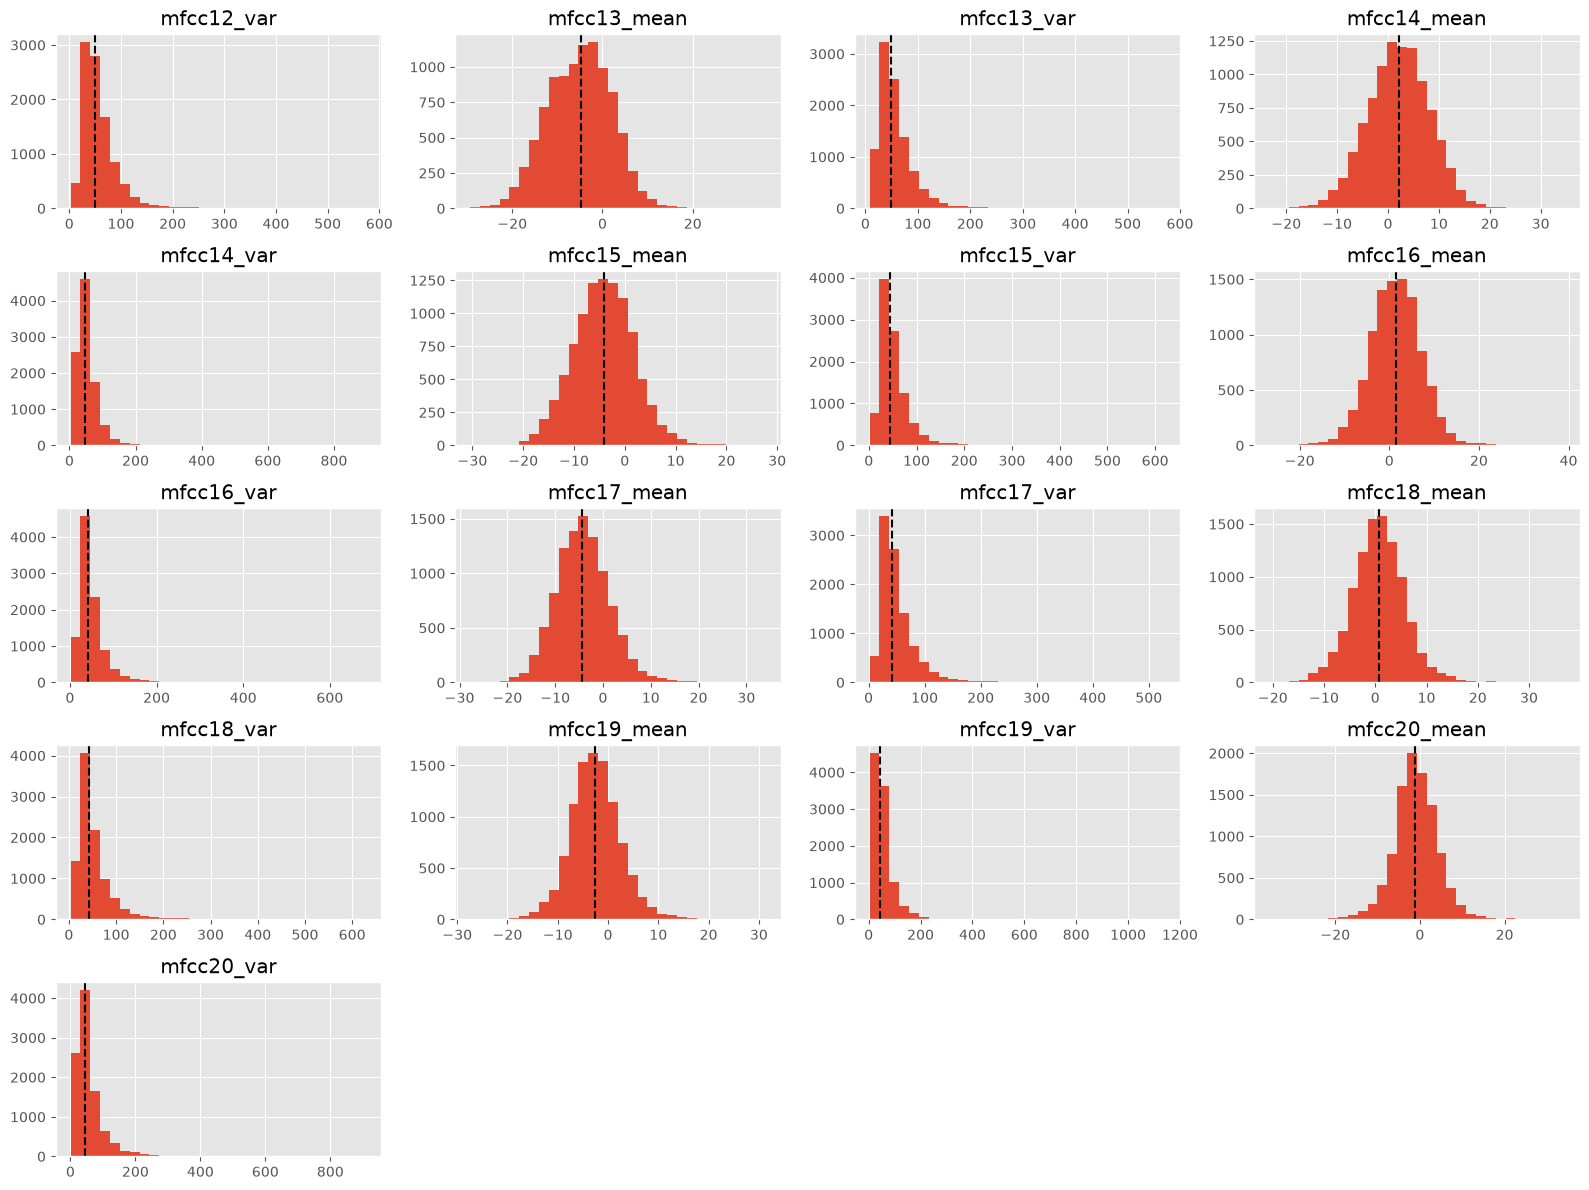

In [20]:
#distributions
with PdfPages("./data/task2_distributions_3.pdf") as pdf:
    for start in range(0, len(num_columns), 20):
        cols=num_columns[start:start+20]
        axes = f3_df[num_columns][cols].hist(bins=30, figsize=(16, 12))

        for ax, col in zip(axes.ravel(), cols):
            median = feature_df_descr_3.loc["50%", col]
            ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
        fig = axes.ravel()[0].figure
        fig.tight_layout()
        pdf.savefig(fig)

        if start + 20 < len(num_columns):
            plt.close(fig)
        last_fig = fig

if last_fig is not None:
    plt.show()

We observe highly unscaled data, some values are centered around 0, while other go up to value of 500. Additionally, we observe again various distributions across the columns.

In [21]:
#variance check
feature_df_descr_3.iloc[2, :].sort_values(ascending=True).head(10)


perceptr_mean              0.001104
harmony_mean               0.001709
rms_var                    0.003487
zero_crossing_rate_var     0.003582
perceptr_var               0.006640
chroma_stft_var            0.009602
harmony_var                0.012562
zero_crossing_rate_mean    0.045561
rms_mean                   0.068610
chroma_stft_mean           0.090567
Name: std, dtype: float64

As for F30, several features have low but non-zero standard deviation and are retained. `length` is constant in F3 (every clip has 66 149 samples), which is another reason it is not a predictor.

In [22]:
#mean check
feature_df_descr_3.iloc[1, :].sort_values(ascending=False).head(5)
mean_max = feature_df_descr_3.iloc[1, :].max()
mean_min = feature_df_descr_3.iloc[1, :].min()
print(f"The highest mean value: {mean_max}, the lowest mean value: {mean_min}")


The highest mean value: 1626083.2254095536, the lowest mean value: -146.3423015410445


Same picture as for F30: the scales differ by many orders of magnitude, so the same log + standard scaling is used.

In [23]:
#min check
feature_df_descr_3.iloc[3, :].sort_values(ascending=True).head(5)

mfcc1_mean   -662.171631
mfcc3_mean   -104.249832
mfcc5_mean    -47.886780
mfcc7_mean    -45.187019
mfcc8_mean    -40.323467
Name: min, dtype: float64

In [24]:
#max check
feature_df_descr_3.iloc[7, :].sort_values(ascending=False).head(10)

rolloff_var                1.298320e+07
spectral_centroid_var      4.794119e+06
spectral_bandwidth_var     1.235143e+06
mfcc1_var                  4.502738e+04
rolloff_mean               9.487446e+03
spectral_centroid_mean     5.432534e+03
mfcc2_var                  5.131987e+03
mfcc3_var                  4.147786e+03
spectral_bandwidth_mean    3.708148e+03
mfcc4_var                  2.303752e+03
Name: max, dtype: float64

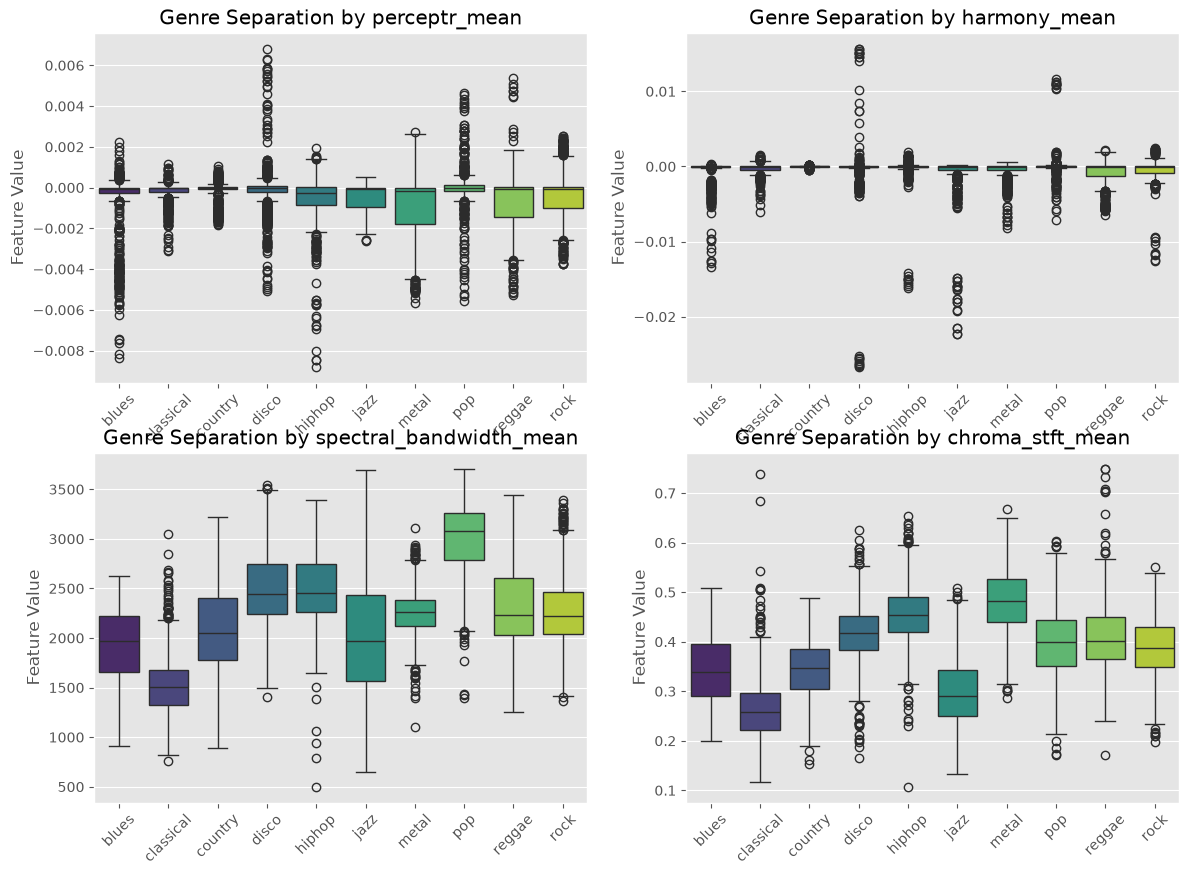

In [25]:
#primary target separation inspection

to_inspect = ["perceptr_mean",
              "harmony_mean",
              "spectral_bandwidth_mean",
              "chroma_stft_mean"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(to_inspect):
    sns.boxplot(data=f3_df, x='label', y=feature, ax=axes[i], hue="label",legend=False, palette='viridis')
    axes[i].set_title(f'Genre Separation by {feature}')
    axes[i].set_ylabel('Feature Value')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)

plt.show()

In [26]:
#heatmaps
def feature_family(name):
    if name.startswith("highlevel_"):
        return "highlevel"
    if name.startswith("loudness_"):
        return "loudness"
    if name.startswith(("rhythm_", "tempotap_")):
        return "rhythm"
    if name.startswith("spectral_"):
        return "spectral"
    if name.startswith("temporal_"):
        return "temporal"
    if name.startswith("timbral_"):
        return "timbral"
    if name.startswith("tonal_"):
        return "tonal"
    if name.startswith("mfcc"):
            return "mfcc"
    if name.startswith("rolloff_"):
                return "rolloff"
    if name.startswith("zero_crossing_rate"):
                    return "zcr"
    return "other"


family_order = [
    "highlevel", "loudness", "rhythm", "spectral",
    "temporal", "timbral", "tonal", "mfcc", "rolloff", "zcr", "other",
]


def plot_family_heatmap(matrix, title, mask_upper=False):
    family_by_feature = {name: feature_family(name) for name in matrix.columns}
    ordered_features = sorted(
        matrix.columns,
        key=lambda name: (family_order.index(family_by_feature[name]), name),
    )
    ordered = matrix.loc[ordered_features, ordered_features]
    families = [family_by_feature[name] for name in ordered_features]
    n_features = len(ordered_features)

    fig, ax = plt.subplots(
        figsize=(max(16, n_features * 0.12), max(14, n_features * 0.12))
    )
    mask = np.triu(np.ones(ordered.shape, dtype=bool)) if mask_upper else None

    sns.heatmap(
        ordered,
        ax=ax,
        mask=mask,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"shrink": 0.65},
    )

    group_positions = {}
    for position, family in enumerate(families):
        group_positions.setdefault(family, []).append(position)

    family_names = list(group_positions)
    family_centers = [
        np.mean(group_positions[family]) + 0.5 for family in family_names
    ]
    boundaries = [
        group_positions[family][-1] + 1 for family in family_names[:-1]
    ]

    for boundary in boundaries:
        ax.axhline(boundary, color="black", linewidth=1)
        ax.axvline(boundary, color="black", linewidth=1)

    top_ax = ax.twiny()
    top_ax.set_xlim(ax.get_xlim())
    top_ax.set_xticks(family_centers)
    top_ax.set_xticklabels(family_names, fontsize=8)
    top_ax.tick_params(axis="x", length=0, pad=4)
    top_ax.spines["top"].set_visible(False)

    right_ax = ax.twinx()
    right_ax.set_ylim(ax.get_ylim())
    right_ax.set_yticks(family_centers)
    right_ax.set_yticklabels(family_names, fontsize=8)
    right_ax.tick_params(axis="y", length=0, pad=4)
    right_ax.spines["right"].set_visible(False)

    feature_font = max(3, min(7, 600 / n_features))
    ax.tick_params(axis="x", labelrotation=90, labelsize=feature_font)
    ax.tick_params(axis="y", labelrotation=0, labelsize=feature_font)
    ax.set_title(title, pad=34)
    fig.subplots_adjust(top=0.92, right=0.88, bottom=0.2, left=0.23)
    plt.show()


Reduced heatmap from 57 to 25 highly correlated features.


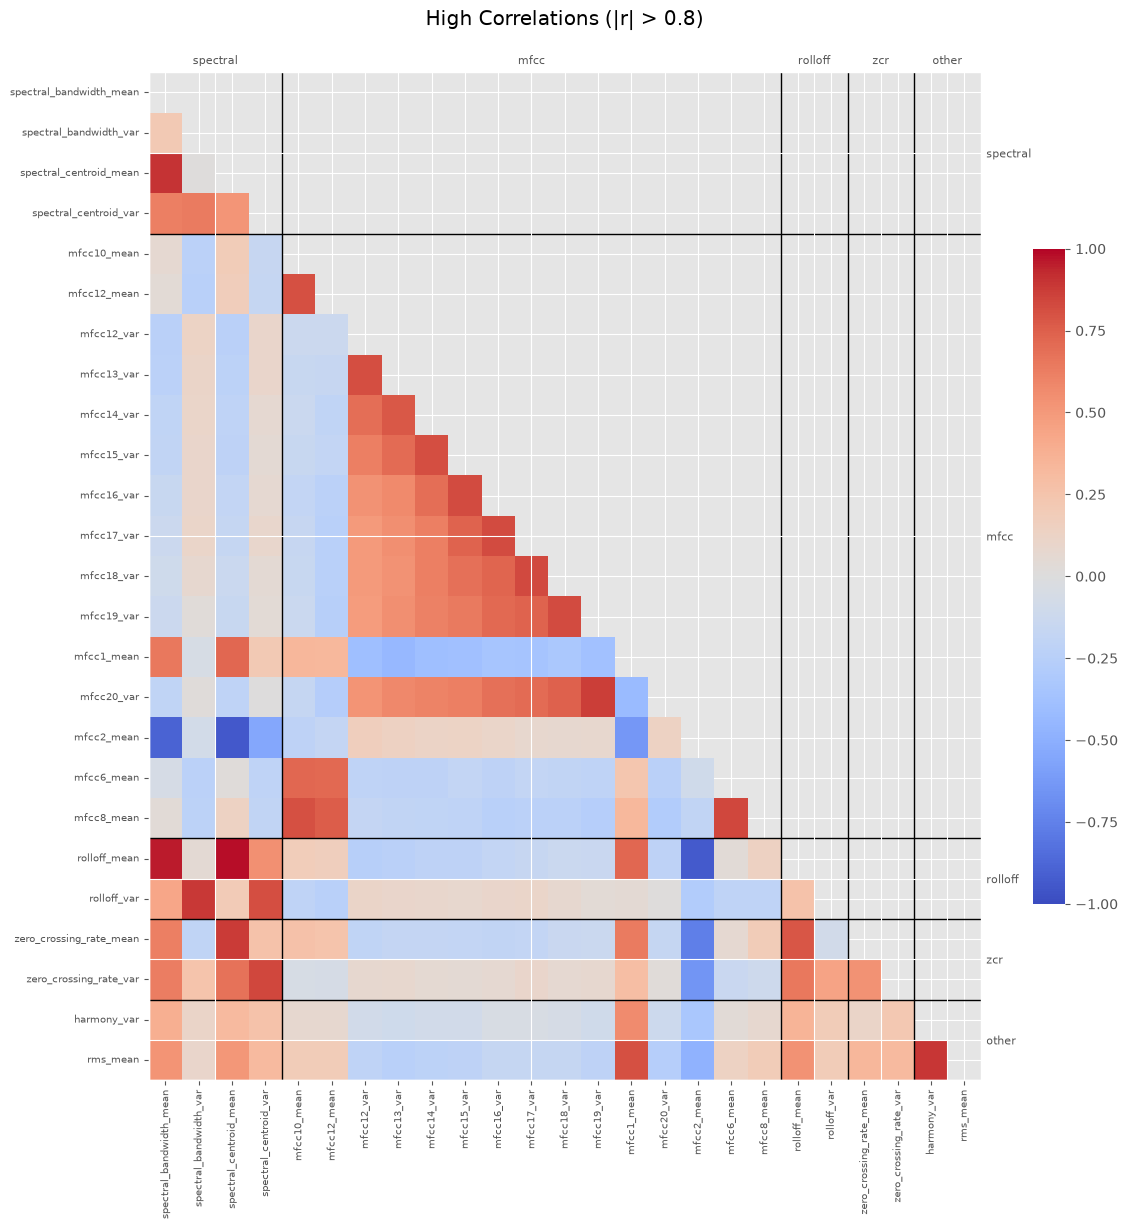

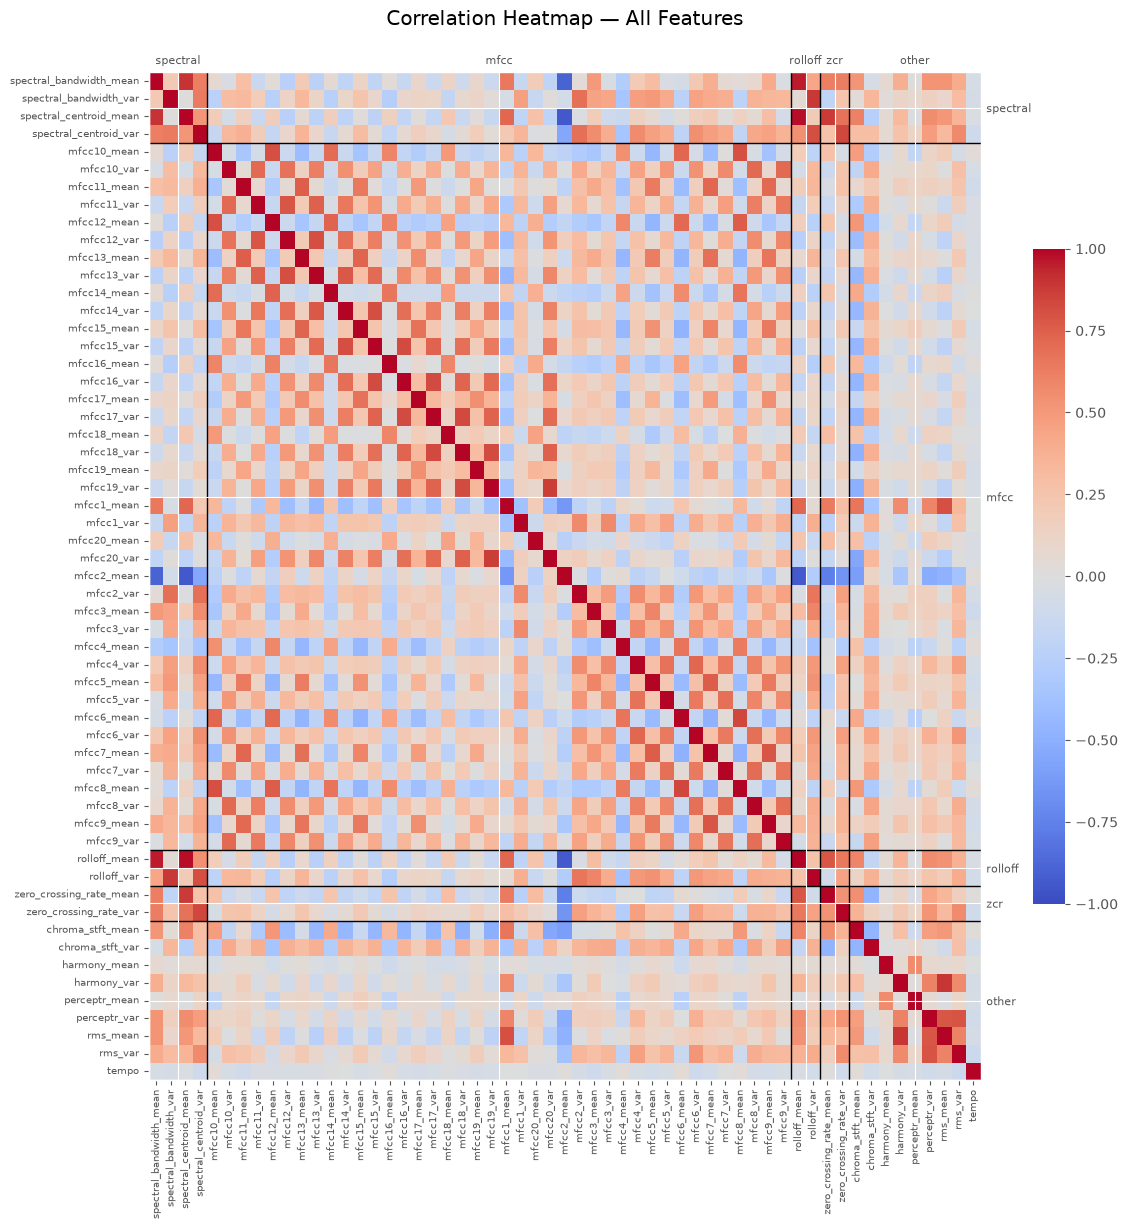

In [27]:
corr_matrix = f30_df[num_columns].corr()   # predictors only (length excluded)
threshold = 0.8

strong_correlations = corr_matrix.abs().where(
    ~np.eye(len(corr_matrix), dtype=bool)
).gt(threshold)
features_with_strong_correlations = strong_correlations.any(axis=0)
high_corr_matrix = corr_matrix.loc[
    features_with_strong_correlations,
    features_with_strong_correlations,
]

print(
    f"Reduced heatmap from {len(num_columns)} to "
    f"{len(high_corr_matrix.columns)} highly correlated features."
)

plot_family_heatmap(
    high_corr_matrix,
    f"High Correlations (|r| > {threshold})",
    mask_upper=True,
)

plot_family_heatmap(
    corr_matrix,
    "Correlation Heatmap — All Features",
)

Correlated groups exist (centroid / bandwidth / rolloff / zero-crossing rate, and the first MFCCs), but with only 57 predictors removing them costs information: a correlation filter at |r| > 0.8 removes 14 of the 57 features, including all rolloff and zero-crossing-rate descriptors. In the experiments this lowered accuracy, so the correlation filter is **not** used in the final pipelines; regularisation (L2 in LR/MLP, C in SVM) handles collinearity instead. `SelectKBest` is kept as a tunable option for the linear and kNN models.

#### Target column

In [28]:
cat_columns

Index(['filename', 'label'], dtype='str')

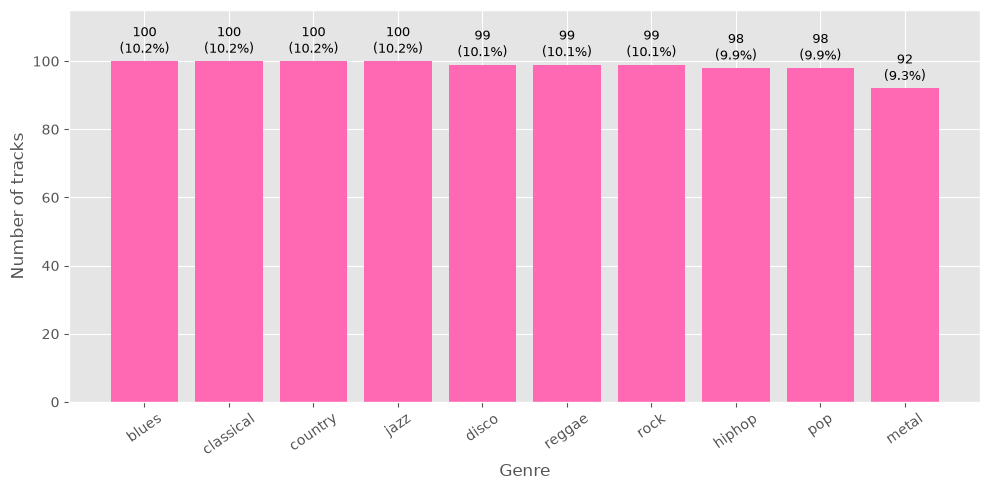

In [49]:
#target column distribution
target_col_name = "label"
counts = f30_df[target_col_name].value_counts()
total = counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color="hotpink")
ax.bar_label(
    bars,
    labels=[f"{count}\n({count / total:.1%})" for count in counts.values],
    padding=3,
    fontsize=9,
)
ax.set(
    title="",
    xlabel="Genre",
    ylabel="Number of tracks",
)
ax.tick_params(axis="x", rotation=35)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

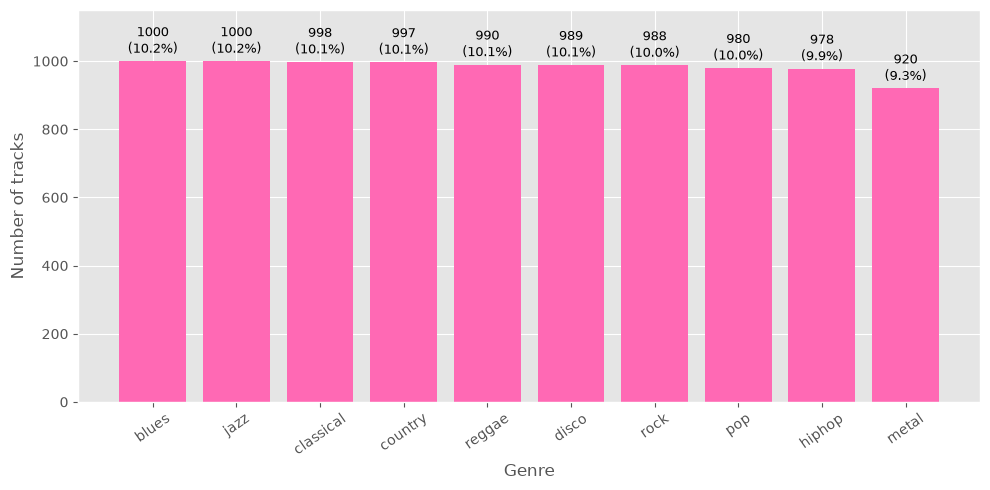

In [50]:
counts = f3_df[target_col_name].value_counts()
total = counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color="hotpink")
ax.bar_label(
    bars,
    labels=[f"{count}\n({count / total:.1%})" for count in counts.values],
    padding=3,
    fontsize=9,
)
ax.set(
    title="",
    xlabel="Genre",
    ylabel="Number of tracks",
)
ax.tick_params(axis="x", rotation=35)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

The genre distribution is similar to the task 1 (100 songs each originally; 91–100 after removing duplicates, metal loses the most). `class_weight='balanced'` is kept where available, but it has very little effect.

## 2. Feature Engineering

In [31]:
import sklearn
sklearn.set_config(transform_output="pandas")
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

In [32]:
# All audio descriptors are numeric. Filenames, song ids, labels, and recording length
# are handled separately and are not passed to the classifiers.
print(f"F30 predictors: {len(FEATURE_COLS)}")
print(f"F3 predictors: {len(FEATURE_COLS)}")
print(f"Log-transformed *_var predictors: {len(var_columns)}")

F30 predictors: 57
F3 predictors: 57
Log-transformed *_var predictors: 28


**Preprocessing used by the models**

* `preprocessor_1` (logistic regression, kNN, SVM, MLP): `log1p` on the `*_var` columns → `StandardScaler` → optional `SelectKBest` (tuned).
* `preprocessor_2` (decision tree, random forest, gradient boosting): no transformation. Trees split on thresholds and are invariant to monotonic transformations, so scaling, log transforms and correlation filtering do not help them.

The `CorrelationFilter` class is kept for reference, but it is not part of the final pipelines.

In [ ]:
# Remove one feature from each pair whose absolute correlation exceeds the threshold.

class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.85):
        self.threshold = threshold

    def fit(self, X, y=None):
        # With transform_output="pandas", X is a DataFrame.
        corr_matrix = X.corr().abs()
        
        # Keep the first feature in column order and compare later features
        # against retained features, avoiding unnecessary drops in correlation chains.
        self.to_drop_ = []
        kept_columns = []
        for column in corr_matrix.columns:
            if any(
                corr_matrix.loc[column, kept] > self.threshold
                for kept in kept_columns
            ):
                self.to_drop_.append(column)
            else:
                kept_columns.append(column)

        # Optional supervised alternative: choose the feature in each pair with the stronger association with y
        # upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        # high_corr_pairs = [
        #     (column, row)
        #     for column in upper.columns
        #     for row in upper.index
        #     if upper.loc[row, column] > self.threshold
        # ]
        # target_series = pd.Series(y, index=X.index)
        # self.to_drop_ = []
        # for column, row in high_corr_pairs:
        #     corr_column = X[column].corr(target_series)
        #     corr_row = X[row].corr(target_series)
        #     if abs(corr_column) < abs(corr_row):
        #         self.to_drop_.append(column)
        #     else:
        #         self.to_drop_.append(row)

        return self

    def transform(self, X):
        return X.drop(columns=[col for col in self.to_drop_ if col in X.columns])

In [59]:
def make_log_var_transformer():
    return ColumnTransformer(
        [("log_var", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), var_columns)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )

preprocessor_1 = Pipeline(steps=[
    ("log_var", make_log_var_transformer()),
    ("scale", StandardScaler()),
    ("feature_selection", SelectKBest(score_func=f_classif, k="all")),
])

# Tree models work on the raw features.
preprocessor_2 = Pipeline(steps=[
    ("log_var", make_log_var_transformer()),
    ("scale", StandardScaler())
])

## 3. Classification

In [35]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

### Training and model selection

In [36]:
# One label encoder for both datasets, so class ids mean the same thing everywhere.
le = LabelEncoder().fit(f30_df["label"])
y_30 = le.transform(f30_df["label"])
y_3 = le.transform(f3_df["label"])

X_30 = f30_df[FEATURE_COLS].copy()
X_3 = f3_df[FEATURE_COLS].copy()

**Split strategy (same songs for both datasets)**

1. A single song-level, stratified 80/20 split is made with `StratifiedGroupKFold` on the song groups. The F30 rows and the F3 clips of the *same* training songs form the two training sets, and likewise for the test sets. This way the 30 s models (whole songs) and the 3 s models (clips) are evaluated on exactly the same held-out songs.
2. The training songs are split into 10 grouped, stratified folds. The F3 folds are derived from the F30 folds (each clip inherits the fold of its song), so the 10-fold CV also uses the same songs per fold for both datasets.
3. Asserts check that no song (or duplicate group) appears on both sides of any split.

In [37]:
songs_df = f30_df[["song_id", "group", "label"]]
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_pos, test_pos = next(outer_split.split(songs_df, songs_df["label"], songs_df["group"]))
train_groups = set(songs_df["group"].iloc[train_pos])

is_train_30 = f30_df["group"].isin(train_groups).to_numpy()
is_train_3 = f3_df["group"].isin(train_groups).to_numpy()

X_train_30, X_test_30 = X_30[is_train_30], X_30[~is_train_30]
y_train_30, y_test_30 = y_30[is_train_30], y_30[~is_train_30]
X_train_3, X_test_3 = X_3[is_train_3], X_3[~is_train_3]
y_train_3, y_test_3 = y_3[is_train_3], y_3[~is_train_3]

assert not set(f30_df["group"][is_train_30]) & set(f30_df["group"][~is_train_30])
assert not set(f3_df["group"][is_train_3]) & set(f3_df["group"][~is_train_3])
assert set(f3_df["song_id"][~is_train_3]) == set(f30_df["song_id"][~is_train_30]), "Test songs differ between F30 and F3"
print(f"Train: {len(X_train_30)} songs / {len(X_train_3)} clips | Test: {len(X_test_30)} songs / {len(X_test_3)} clips")

Train: 788 songs / 7871 clips | Test: 197 songs / 1969 clips


In [38]:
# 10 grouped folds on the training songs, shared by F30 and F3
inner_cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
train_songs = f30_df[is_train_30].reset_index(drop=True)
fold_of_group = {}
for k, (_, val_pos) in enumerate(inner_cv.split(train_songs, train_songs["label"], train_songs["group"])):
    for g in train_songs["group"].iloc[val_pos]:
        fold_of_group[g] = k

def folds_for(groups_train):
    fold = groups_train.map(fold_of_group).to_numpy()
    return [(np.where(fold != k)[0], np.where(fold == k)[0]) for k in range(10)]

cv_splits_30 = folds_for(f30_df["group"][is_train_30])
cv_splits_3 = folds_for(f3_df["group"][is_train_3])

for name, splits, groups in [("F30", cv_splits_30, f30_df["group"][is_train_30]),
                             ("F3", cv_splits_3, f3_df["group"][is_train_3])]:
    for tr, va in splits:
        assert not set(groups.iloc[tr]) & set(groups.iloc[va]), f"{name}: a song is on both sides of a CV fold"
print("All CV folds are song-disjoint.")

All CV folds are song-disjoint.


**Evaluation unit**

* F30 models are trained and evaluated on full songs (one row per 30 s track).
* F3 models are trained and evaluated on individual 3 s clips. Every clip is scored on its own; the clip accuracy is the metric for F3.

Both use validaiotn accuracy for model selection (`GridSearchCV`, `refit=True`).

In [39]:
data = {
    "30": (X_train_30, y_train_30, cv_splits_30),
    "3": (X_train_3, y_train_3, cv_splits_3),
}
unit = {"30": "song", "3": "clip"}

model_searches = {}
cv_results = []


def fold_scores(search):
    i = search.best_index_
    return np.array([search.cv_results_[f"split{k}_test_score"][i] for k in range(search.n_splits_)])


def tune_model(pipeline, param_grid, model_name, dataset):
    X_train, y_train, cv_splits = data[dataset]
    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=param_grid,
        cv=cv_splits,
        scoring="accuracy",
        refit=True,
        return_train_score=True,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    i = search.best_index_
    res = search.cv_results_
    row = {
        "Model": model_name,
        "Dataset": dataset,
        "Unit": unit[dataset],
        "CV train acc": res["mean_train_score"][i],
        "CV val acc": res["mean_test_score"][i],
        "CV val std": res["std_test_score"][i],
        "Best parameters": search.best_params_,
    }
    print(f"\n{model_name} ({unit[dataset]} level)")
    print(f"Best parameters: {search.best_params_}")
    print(f"10-fold CV accuracy: train={row['CV train acc']:.3f}, "
          f"validation={row['CV val acc']:.3f} ± {row['CV val std']:.3f}")
    model_searches[model_name] = search
    cv_results.append(row)
    return search


def tune_both(pipeline, param_grid, base_name):
    return {d: tune_model(pipeline, param_grid, f"{base_name}_{d}", d) for d in ("30", "3")}

### Logistic Regression: `lr_30` and `lr_3`

In [ ]:
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=42)),
])

# lbfgs + L2 converges quickly on standardised features (saga + L1 did not converge before)
lr_param_grid = {
    "preprocessor__feature_selection__k": [10, 20, 30, 45, "all"],  
    "classifier__C": [0.03, 0.1, 0.3, 1.0],
}

lr = tune_both(lr_pipeline, lr_param_grid, "lr")
lr_30, lr_3 = lr["30"], lr["3"]


lr_30 (song level)
Best parameters: {'classifier__C': 0.3, 'preprocessor__feature_selection__k': 'all'}
10-fold CV accuracy: train=0.877, validation=0.718 ± 0.053

lr_3 (clip level)
Best parameters: {'classifier__C': 0.1, 'preprocessor__feature_selection__k': 'all'}
10-fold CV accuracy: train=0.754, validation=0.670 ± 0.033


### kNN: `knn_30` and `knn_3`

In [ ]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", KNeighborsClassifier(weights="distance")),
])

knn_param_grid = {
    "preprocessor__feature_selection__k": [15, 30, "all"],          
    "classifier__n_neighbors": [5, 9, 15, 25],
    "classifier__p": [1, 2],  # 1 = Manhattan, 2 = Euclidean
}

knn = tune_both(knn_pipeline, knn_param_grid, "knn")
knn_30, knn_3 = knn["30"], knn["3"]


knn_30 (song level)
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'preprocessor__feature_selection__k': 'all'}
10-fold CV accuracy: train=1.000, validation=0.704 ± 0.047

knn_3 (clip level)
Best parameters: {'classifier__n_neighbors': 15, 'classifier__p': 1, 'preprocessor__feature_selection__k': 'all'}
10-fold CV accuracy: train=1.000, validation=0.678 ± 0.031


### Decision Tree: `dt_30` and `dt_3`

In [60]:
dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_2),
    ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=42)),
])

dt_param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [8, 12, None],
    "classifier__min_samples_leaf": [1, 5, 10],
}

dt = tune_both(dt_pipeline, dt_param_grid, "dt")
dt_30, dt_3 = dt["30"], dt["3"]


dt_30 (song level)
Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 1}
10-fold CV accuracy: train=0.933, validation=0.511 ± 0.042

dt_3 (clip level)
Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 12, 'classifier__min_samples_leaf': 1}
10-fold CV accuracy: train=0.954, validation=0.520 ± 0.024


### Random Forest: `rf_30` and `rf_3`

In [61]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_2),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=1,  # GridSearchCV handles parallelism
    )),
])

rf_param_grid = {
    "classifier__max_features": ["sqrt", 0.3],
    "classifier__min_samples_leaf": [1, 3],
}

rf = tune_both(rf_pipeline, rf_param_grid, "rf")
rf_30, rf_3 = rf["30"], rf["3"]


rf_30 (song level)
Best parameters: {'classifier__max_features': 0.3, 'classifier__min_samples_leaf': 1}
10-fold CV accuracy: train=1.000, validation=0.714 ± 0.045

rf_3 (clip level)
Best parameters: {'classifier__max_features': 0.3, 'classifier__min_samples_leaf': 1}
10-fold CV accuracy: train=1.000, validation=0.700 ± 0.020


### Gradient Boosting (HistGradientBoosting): `hgb_30` and `hgb_3`

In [62]:
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_2),
    ("classifier", HistGradientBoostingClassifier(max_iter=300, random_state=42)),
])

hgb_param_grid = {
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_leaf_nodes": [15, 31],
}

hgb = tune_both(hgb_pipeline, hgb_param_grid, "hgb")
hgb_30, hgb_3 = hgb["30"], hgb["3"]


hgb_30 (song level)
Best parameters: {'classifier__learning_rate': 0.05, 'classifier__max_leaf_nodes': 15}
10-fold CV accuracy: train=1.000, validation=0.731 ± 0.037

hgb_3 (clip level)
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_leaf_nodes': 31}
10-fold CV accuracy: train=1.000, validation=0.741 ± 0.019


### SVM (RBF kernel): `svm_30` and `svm_3`

In [45]:
svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", SVC(kernel="rbf", gamma="scale", class_weight="balanced", random_state=42)),
])

svm_param_grid = {
    "classifier__C": [1, 3, 10, 30],
}

svm = tune_both(svm_pipeline, svm_param_grid, "svm")
svm_30, svm_3 = svm["30"], svm["3"]


svm_30 (song level)
Best parameters: {'classifier__C': 10}
10-fold CV accuracy: train=1.000, validation=0.755 ± 0.031

svm_3 (clip level)
Best parameters: {'classifier__C': 3}
10-fold CV accuracy: train=0.989, validation=0.731 ± 0.022


### ANN (MLP): `mlp_30` and `mlp_3`

In [63]:
mlp_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_1),
    ("classifier", MLPClassifier(
        solver="adam",
        max_iter=500,
        early_stopping=False,
        random_state=42,
    )),
])

mlp_param_grid = {
    "classifier__hidden_layer_sizes": [(64, 32), (128, 64), (256, 128)],
    "classifier__alpha": [0.3, 1.0, 3.0],
}

mlp = tune_both(mlp_pipeline, mlp_param_grid, "mlp")
mlp_30, mlp_3 = mlp["30"], mlp["3"]

/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/lidiawisniewska/Desktop/SMC/ML-for-Sound-and-Music/.ml/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarn


mlp_30 (song level)
Best parameters: {'classifier__alpha': 3.0, 'classifier__hidden_layer_sizes': (64, 32)}
10-fold CV accuracy: train=0.969, validation=0.750 ± 0.041

mlp_3 (clip level)
Best parameters: {'classifier__alpha': 1.0, 'classifier__hidden_layer_sizes': (256, 128)}
10-fold CV accuracy: train=0.983, validation=0.720 ± 0.030


## 4. Evaluation

In [84]:
test_sets = {"30": (X_test_30, y_test_30), "3": (X_test_3, y_test_3)}
test_predictions = {}
evaluation_rows = []
for row in cv_results:
    name, d = row["Model"], row["Dataset"]
    X_test, y_test = test_sets[d]
    test_predictions[name] = model_searches[name].predict(X_test)
    evaluation_rows.append({**row, "Test acc": accuracy_score(y_test, test_predictions[name])})

evaluation_summary = (pd.DataFrame(evaluation_rows)
                      .sort_values(["Dataset", "CV val acc"], ascending=[False, False])
                      .reset_index(drop=True))
for d, title in [("30", "F30 — evaluated on full test songs"), ("3", "F3 — evaluated on 3 s test clips")]:
    print(title)
    display(evaluation_summary[evaluation_summary["Dataset"] == d]
            .drop(columns=["Best parameters", "Dataset"]).round(3))
display(evaluation_summary[["Model", "Best parameters"]])
evaluation_summary.drop(columns="Best parameters").round(4).to_csv("evaluation_summary_task2.csv", index=False)

F30 — evaluated on full test songs


,Model,Unit,CV train acc,CV val acc,CV val std,Test acc
0,svm_30,song,1.000,0.755,0.031,0.741
1,mlp_30,song,0.969,0.750,0.041,0.695
2,hgb_30,song,1.000,0.731,0.037,0.716
3,lr_30,song,0.877,0.718,0.053,0.716
4,rf_30,song,1.000,0.714,0.045,0.650
5,knn_30,song,1.000,0.704,0.047,0.650
6,dt_30,song,0.933,0.511,0.042,0.487


F3 — evaluated on 3 s test clips


,Model,Unit,CV train acc,CV val acc,CV val std,Test acc
7,hgb_3,clip,1.000,0.741,0.019,0.732
8,svm_3,clip,0.989,0.731,0.022,0.706
9,mlp_3,clip,0.983,0.720,0.030,0.714
10,rf_3,clip,1.000,0.700,0.020,0.669
11,knn_3,clip,1.000,0.678,0.031,0.656
12,lr_3,clip,0.754,0.670,0.033,0.670
13,dt_3,clip,0.954,0.520,0.024,0.478


,Model,Best parameters
0,svm_30,{'classifier__C': 10}
1,mlp_30,"{'classifier__alpha': 3.0, 'classifier__hidden..."
2,hgb_30,"{'classifier__learning_rate': 0.05, 'classifie..."
3,lr_30,"{'classifier__C': 0.3, 'preprocessor__feature_..."
4,rf_30,"{'classifier__max_features': 0.3, 'classifier_..."
5,knn_30,"{'classifier__n_neighbors': 5, 'classifier__p'..."
6,dt_30,"{'classifier__criterion': 'entropy', 'classifi..."
7,hgb_3,"{'classifier__learning_rate': 0.1, 'classifier..."
8,svm_3,{'classifier__C': 3}
9,mlp_3,"{'classifier__alpha': 1.0, 'classifier__hidden..."


Best 30 s model by CV: svm_30 | CV=0.755 | test=0.741 (song level)
Best 3 s model by CV: hgb_3 | CV=0.741 | test=0.732 (clip level)


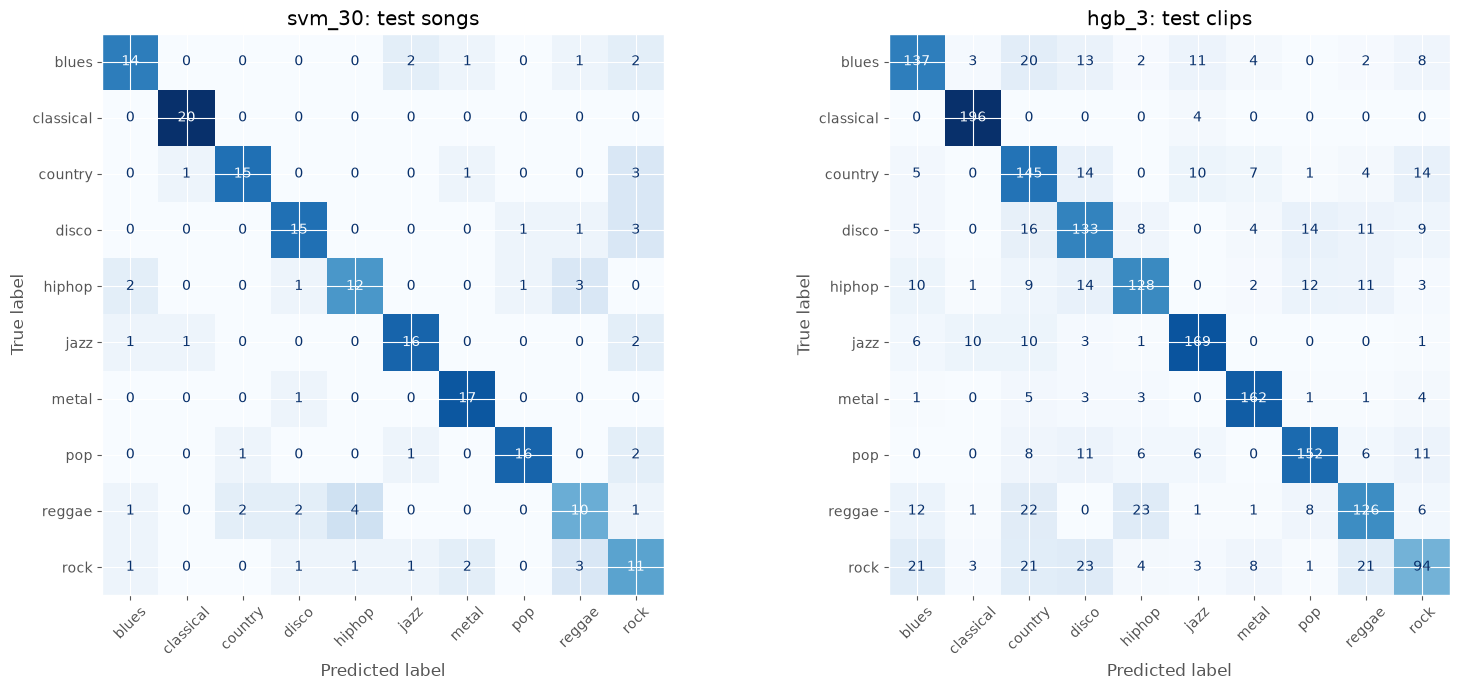

In [85]:
best_model = {
    d: evaluation_summary[evaluation_summary["Dataset"] == d].iloc[0]["Model"] for d in ("30", "3")
}
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, d in zip(axes, ("30", "3")):
    name = best_model[d]
    _, y_test = test_sets[d]
    row = evaluation_summary.set_index("Model").loc[name]
    print(f"Best {d} s model by CV: {name} | CV={row['CV val acc']:.3f} | test={row['Test acc']:.3f} ({unit[d]} level)")
    ConfusionMatrixDisplay(confusion_matrix(y_test, test_predictions[name]), display_labels=le.classes_).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}: test {unit[d]}s")
plt.tight_layout()
plt.show()

## 5. Research questions

1. [Is the 3 s accuracy real or inflated?](#rq1)
2. [Which songs are misclassified by every model?](#rq2)
3. [Which feature families matter most?](#rq3)
5. [Does feature selection reduce overfitting or just cost?](#rq4)

In [51]:
from scipy import stats
from sklearn.model_selection import cross_val_score

<a id="rq1"></a>
### RQ1. Is the 3 s accuracy real or inflated?

Clips of the same song are very similar, so a random split of the clips puts near-copies of a validation clip into the training set. We compare, on the same F3 training data and with the same tuned pipelines:

* **grouped CV** — the 10 song-disjoint folds used for tuning;
* **random CV** — an ordinary `StratifiedKFold` over clips (clips of one song on both sides).

A large gap means the random-split number measures recognition of already-seen songs, not genre classification. We also check that the grouped CV estimate agrees with the held-out test clips, which come from songs never used in training or tuning. kNN is included because it is the most sensitive to near-duplicates.

In [52]:
random_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
rq1_models = list(dict.fromkeys([best_model["3"], "knn_3", "lr_3"]))
rq1_rows = []
for name in rq1_models:
    search = model_searches[name]
    random_scores = cross_val_score(clone(search.best_estimator_), X_train_3, y_train_3,
                                    cv=random_cv, scoring="accuracy", n_jobs=-1)
    row = evaluation_summary.set_index("Model").loc[name]
    rq1_rows.append({
        "Model": name,
        "Random clip CV (leaky)": random_scores.mean(),
        "Song-grouped CV": row["CV val acc"],
        "Held-out test clips": row["Test acc"],
        "Inflation (random - grouped)": random_scores.mean() - row["CV val acc"],
    })
rq1 = pd.DataFrame(rq1_rows)
display(rq1.round(3))

,Model,Random clip CV (leaky),Song-grouped CV,Held-out test clips,Inflation (random - grouped)
0,hgb_3,0.931,0.739,0.734,0.192
1,knn_3,0.892,0.678,0.656,0.214
2,lr_3,0.729,0.670,0.670,0.060


<a id="rq2"></a>
### RQ2. Which songs are misclassified by every model?

For F30, a test song is "always wrong" if all F30 models mispredict it. For F3, the same is checked per test clip across all F3 models; the always-wrong clips are then counted per song, to see whether errors concentrate in a few songs. Songs that every model gets wrong are candidates for label noise, genre ambiguity or atypical recordings (GTZAN is known to contain mislabeled and distorted tracks).

In [53]:
names_30 = [n for n in test_predictions if n.endswith("_30")]
names_3 = [n for n in test_predictions if n.endswith("_3")]

# F30: songs
pred_30 = pd.DataFrame({n: le.inverse_transform(test_predictions[n]) for n in names_30},
                       index=f30_df.loc[X_test_30.index, "song_id"])
true_30 = pd.Series(le.inverse_transform(y_test_30), index=pred_30.index, name="true")
always_wrong_30 = pred_30.ne(true_30, axis=0).all(axis=1)
hard_30 = pred_30[always_wrong_30].assign(true=true_30[always_wrong_30])
hard_30["most common prediction"] = pred_30[always_wrong_30].mode(axis=1)[0]
print(f"F30: {always_wrong_30.sum()} of {len(pred_30)} test songs are misclassified by all {len(names_30)} models")
display(hard_30[["true", "most common prediction"] + names_30].sort_values("true"))

F30: 17 of 197 test songs are misclassified by all 7 models


,true,most common prediction,lr_30,knn_30,dt_30,rf_30,hgb_30,svm_30,mlp_30
song_id,,,,,,,,,
blues.00098,blues,metal,metal,disco,disco,metal,metal,metal,metal
country.00030,country,classical,classical,classical,rock,jazz,classical,classical,classical
country.00053,country,rock,rock,rock,blues,rock,rock,rock,rock
country.00092,country,metal,metal,rock,blues,metal,metal,metal,metal
disco.00020,disco,rock,rock,reggae,rock,country,country,rock,rock
hiphop.00023,hiphop,blues,blues,blues,disco,rock,metal,blues,blues
hiphop.00039,hiphop,pop,reggae,pop,pop,pop,pop,pop,reggae
hiphop.00044,hiphop,reggae,reggae,reggae,pop,reggae,pop,reggae,reggae
jazz.00001,jazz,classical,classical,classical,classical,classical,classical,classical,classical


F3: 219 of 1969 test clips (11.1%) are misclassified by all 7 models


,true,clips,always-wrong clips,most common wrong prediction
song_id,,,,
pop.00079,pop,10,10,country
hiphop.00044,hiphop,10,9,country
metal.00008,metal,10,9,country
disco.00020,disco,10,8,country
reggae.00094,reggae,10,8,country
rock.00014,rock,10,7,reggae
disco.00041,disco,10,7,country
rock.00013,rock,10,7,blues
pop.00012,pop,10,7,disco


Songs always wrong in F30 that also have >= 5 always-wrong clips in F3: ['blues.00098', 'country.00053', 'country.00092', 'disco.00020', 'hiphop.00023', 'hiphop.00044', 'metal.00008', 'pop.00012', 'reggae.00094', 'rock.00031', 'rock.00038']


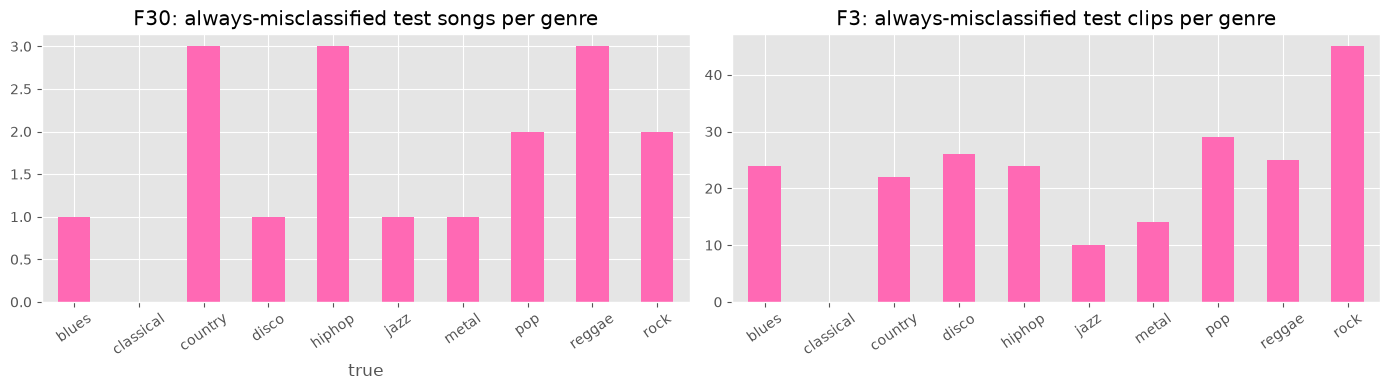

In [54]:
# F3: clips
pred_3 = pd.DataFrame({n: le.inverse_transform(test_predictions[n]) for n in names_3}, index=X_test_3.index)
true_3 = pd.Series(le.inverse_transform(y_test_3), index=X_test_3.index)
always_wrong_3 = pred_3.ne(true_3, axis=0).all(axis=1)
clip_song = f3_df.loc[X_test_3.index, "song_id"]
per_song = pd.DataFrame({
    "true": true_3.groupby(clip_song).first(),
    "clips": clip_song.value_counts(),
    "always-wrong clips": always_wrong_3.groupby(clip_song).sum(),
})
wrong_votes = pred_3[always_wrong_3].stack()
wrong_votes.index = clip_song.loc[wrong_votes.index.get_level_values(0)].to_numpy()
per_song["most common wrong prediction"] = wrong_votes.groupby(level=0).agg(lambda s: s.mode()[0])
print(f"F3: {always_wrong_3.sum()} of {len(pred_3)} test clips ({always_wrong_3.mean():.1%}) are misclassified by all {len(names_3)} models")
hard_3 = per_song[per_song["always-wrong clips"] > 0].sort_values("always-wrong clips", ascending=False)
display(hard_3.head(20))

overlap = sorted(set(hard_30.index) & set(hard_3[hard_3["always-wrong clips"] >= 5].index))
print(f"Songs always wrong in F30 that also have >= 5 always-wrong clips in F3: {overlap}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hard_30["true"].value_counts().reindex(le.classes_, fill_value=0).plot.bar(ax=axes[0], color="hotpink")
axes[0].set_title("F30: always-misclassified test songs per genre")
true_3[always_wrong_3].value_counts().reindex(le.classes_, fill_value=0).plot.bar(ax=axes[1], color="hotpink")
axes[1].set_title("F3: always-misclassified test clips per genre")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

<a id="rq3"></a>
### RQ3. Which feature families matter most?

Features are grouped into acoustic families. Importance is measured with **grouped permutation importance** on the held-out test set of the best model of each dataset: all columns of one family are shuffled together (the same row permutation for the whole block), and the drop in test accuracy is recorded over several repeats. Permuting a family as a block avoids the main weakness of per-feature permutation importance with correlated features (e.g. centroid / rolloff / bandwidth), where the model can fall back on a correlated partner and every member looks unimportant.

Families with more columns can carry more information, so the number of features per family is shown as well.

{'chroma': 2, 'energy (rms)': 2, 'spectral shape': 6, 'zero-crossing rate': 2, 'harmonic/percussive': 4, 'tempo': 1, 'mfcc means': 20, 'mfcc variances': 20}
svm_30: baseline test accuracy 0.741


,family,n_features,accuracy drop,std
6,mfcc means,20,0.337,0.026
7,mfcc variances,20,0.264,0.026
2,spectral shape,6,0.101,0.019
0,chroma,2,0.065,0.018
4,harmonic/percussive,4,0.046,0.019
1,energy (rms),2,0.025,0.015
5,tempo,1,0.020,0.014
3,zero-crossing rate,2,0.011,0.013


hgb_3: baseline test accuracy 0.734


,family,n_features,accuracy drop,std
6,mfcc means,20,0.254,0.008
4,harmonic/percussive,4,0.195,0.005
7,mfcc variances,20,0.107,0.006
2,spectral shape,6,0.041,0.005
0,chroma,2,0.034,0.007
1,energy (rms),2,0.024,0.005
5,tempo,1,0.016,0.003
3,zero-crossing rate,2,0.001,0.003


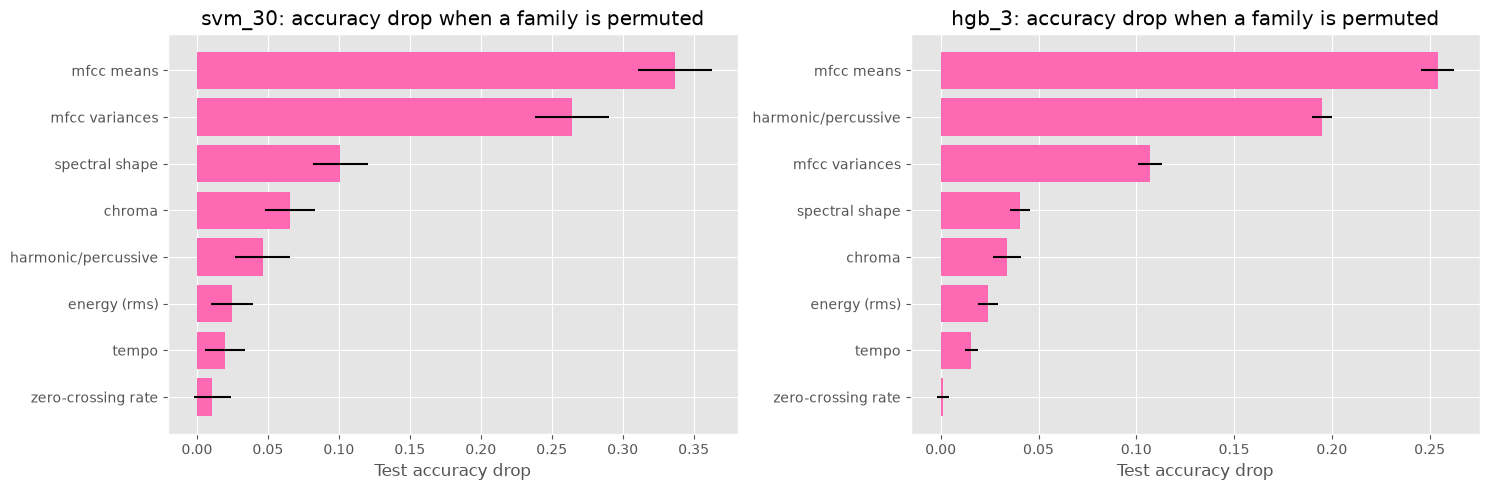

In [55]:
def gtzan_family(name):
    if name.startswith("chroma"):                      return "chroma"
    if name.startswith("rms"):                         return "energy (rms)"
    if name.startswith(("spectral_", "rolloff")):      return "spectral shape"
    if name.startswith("zero_crossing"):               return "zero-crossing rate"
    if name.startswith(("harmony", "perceptr")):       return "harmonic/percussive"
    if name == "tempo":                                return "tempo"
    if name.startswith("mfcc") and name.endswith("_mean"): return "mfcc means"
    if name.startswith("mfcc") and name.endswith("_var"):  return "mfcc variances"
    return "other"

families = {}
for c in FEATURE_COLS:
    families.setdefault(gtzan_family(c), []).append(c)
assert "other" not in families
print({k: len(v) for k, v in families.items()})


def family_permutation_importance(estimator, X, y, families, n_repeats=10, seed=42):
    rng = np.random.default_rng(seed)
    baseline = accuracy_score(y, estimator.predict(X))
    rows = []
    for family, cols in families.items():
        drops = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            drops.append(baseline - accuracy_score(y, estimator.predict(X_perm)))
        rows.append({"family": family, "n_features": len(cols),
                     "accuracy drop": np.mean(drops), "std": np.std(drops)})
    return baseline, pd.DataFrame(rows).sort_values("accuracy drop", ascending=False)


rq3 = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, d, reps in zip(axes, ("30", "3"), (20, 5)):
    name = best_model[d]
    X_test, y_test = test_sets[d]
    baseline, imp = family_permutation_importance(model_searches[name].best_estimator_, X_test, y_test,
                                                  families, n_repeats=reps)
    rq3[d] = imp
    print(f"{name}: baseline test accuracy {baseline:.3f}")
    display(imp.round(3))
    ax.barh(imp["family"], imp["accuracy drop"], xerr=imp["std"], color="hotpink")
    ax.invert_yaxis()
    ax.set(title=f"{name}: accuracy drop when a family is permuted", xlabel="Test accuracy drop")
plt.tight_layout()
plt.show()

<a id="rq4"></a>
### RQ4. Does feature selection reduce overfitting or just cost?

`SelectKBest` (ANOVA F-score, fitted inside each training fold) is part of the logistic-regression and kNN grids. For every value of *k* we take the best remaining hyper-parameters and compare the mean train accuracy, validation accuracy, the train–validation gap (overfitting) and the fit time. Feature selection *reduces overfitting* if the gap shrinks while validation accuracy stays the same or improves; it *just costs* if validation accuracy falls along with the gap. (kNN with distance weights always has train accuracy 1, so for kNN only the validation curve is informative.)

lr_30


,k,n_features,train acc,val acc,gap (train - val),fit time (s)
0,10,10,0.593,0.556,0.037,0.028
1,20,20,0.720,0.660,0.060,0.027
2,30,30,0.802,0.702,0.100,0.036
3,45,45,0.860,0.713,0.147,0.040
4,all,57,0.877,0.718,0.158,0.036


lr_3


,k,n_features,train acc,val acc,gap (train - val),fit time (s)
0,10,10,0.551,0.520,0.031,0.227
1,20,20,0.648,0.600,0.047,0.235
2,30,30,0.695,0.634,0.061,0.290
3,45,45,0.740,0.661,0.080,0.370
4,all,57,0.754,0.670,0.084,0.248


knn_30


,k,n_features,train acc,val acc,gap (train - val),fit time (s)
0,15,15,1.0,0.617,0.383,0.026
1,30,30,1.0,0.687,0.313,0.012
2,all,57,1.0,0.704,0.296,0.011


knn_3


,k,n_features,train acc,val acc,gap (train - val),fit time (s)
0,15,15,1.0,0.588,0.412,0.023
1,30,30,1.0,0.643,0.357,0.021
2,all,57,1.0,0.678,0.322,0.020


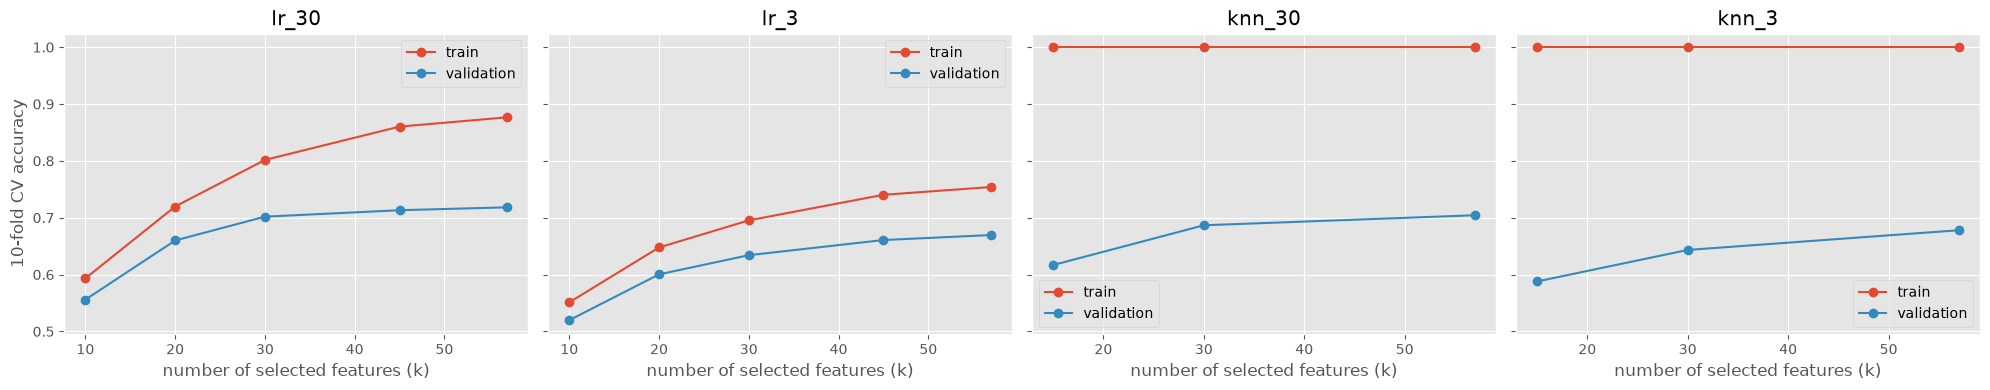

,model,best k < all,Δ val acc (k vs all),Δ gap (k vs all),Δ fit time (s)
0,lr_30,45,-0.005,-0.011,0.004
1,lr_3,45,-0.009,-0.005,0.122
2,knn_30,30,-0.018,0.018,0.001
3,knn_3,30,-0.035,0.035,0.001


In [57]:
def selection_effect(search):
    res = pd.DataFrame(search.cv_results_)
    res["k"] = res["param_preprocessor__feature_selection__k"].astype(str)
    best_per_k = res.loc[res.groupby("k")["mean_test_score"].idxmax()]
    out = pd.DataFrame({
        "k": best_per_k["k"],
        "n_features": best_per_k["k"].replace("all", str(len(FEATURE_COLS))).astype(int),
        "train acc": best_per_k["mean_train_score"],
        "val acc": best_per_k["mean_test_score"],
        "gap (train - val)": best_per_k["mean_train_score"] - best_per_k["mean_test_score"],
        "fit time (s)": best_per_k["mean_fit_time"],
    })
    return out.sort_values("n_features").reset_index(drop=True)


rq5 = {}
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, name in zip(axes, ["lr_30", "lr_3", "knn_30", "knn_3"]):
    eff = selection_effect(model_searches[name])
    rq5[name] = eff
    print(name); display(eff.round(3))
    ax.plot(eff["n_features"], eff["train acc"], "o-", label="train")
    ax.plot(eff["n_features"], eff["val acc"], "o-", label="validation")
    ax.set(title=name, xlabel="number of selected features (k)")
    ax.legend()
axes[0].set_ylabel("10-fold CV accuracy")
plt.tight_layout()
plt.show()

summary = []
for name, eff in rq5.items():
    full = eff[eff["k"] == "all"].iloc[0]
    sel = eff[eff["k"] != "all"].sort_values("val acc", ascending=False).iloc[0]
    summary.append({"model": name, "best k < all": sel["k"],
                    "Δ val acc (k vs all)": sel["val acc"] - full["val acc"],
                    "Δ gap (k vs all)": sel["gap (train - val)"] - full["gap (train - val)"],
                    "Δ fit time (s)": sel["fit time (s)"] - full["fit time (s)"]})
display(pd.DataFrame(summary).round(3))

### Saving fitted models

In [86]:
from pathlib import Path
import joblib
import sklearn

models_dir = Path("models")
if not models_dir.exists() and Path("lab1").is_dir():
    models_dir = Path("lab1") / models_dir
models_dir.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "models": {name: search.best_estimator_ for name, search in model_searches.items()},
    "label_encoder": le,
    "feature_columns": FEATURE_COLS,
    "log_var_columns": var_columns,
    "dropped_duplicate_songs": sorted(songs_to_drop),
    "test_songs": sorted(f30_df.loc[~is_train_30, "song_id"]),
    "best_parameters": {name: search.best_params_ for name, search in model_searches.items()},
    "sklearn_version": sklearn.__version__,
}
model_path = models_dir / "genre_classifiers_task2.joblib"
joblib.dump(model_artifact, model_path)
print(f"Saved {len(model_artifact['models'])} fitted models to {model_path}")

Saved 14 fitted models to models/genre_classifiers_task2.joblib
